# F1 Podium Prediction (Milestone 1)

For every driver in every race, predict whether they finish on the podium (`positionOrder <= 3`).
The prediction is made **after qualifying and before the start**, so only information known at that moment can be an input.
Anything from the race itself (finishing position, points, laps, retirement reason) would be **leakage**.

| Section | Content |
|---|---|
| 1–2 | Setup, loading the 14 tables |
| 3–5 | EDA before cleaning: first look, missing values, key checks, duplicates |
| 6 | Cleaning (on copies) and the data after cleaning |
| 7 | Target and pre-race cutoff |
| 8 | The three data-engineering questions |
| 9–11 | Modeling table, candidate features, preprocessing, feature selection |
| 12–14 | Baseline, logistic regression, random forest, neural network, test results |
| 15 | Experiments: feature-group ablation, preprocessing order |
| 16 | Explainability (permutation importance, SHAP and LIME for every model) |
| 17 | Inference functions (one per model) |
| 18 | Limitations |

## 1. Setup

In [1]:
%pip install -q shap lime missingno
%matplotlib inline
import glob
import warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*(IProgress|sklearn.utils.parallel.delayed).*")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, f1_score,
                             precision_score, recall_score, accuracy_score, confusion_matrix)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import shap
from lime.lime_tabular import LimeTabularExplainer

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# Kaggle keeps the CSVs under /kaggle/input, locally they are in data/raw
kaggle = glob.glob("/kaggle/input/**/results.csv", recursive=True)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = Path(kaggle[0]).parent if kaggle else ROOT / "data" / "raw"
FIG_DIR = (Path("/kaggle/working") if kaggle else ROOT / "notebooks" / "_working_local") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

Note: you may need to restart the kernel to use updated packages.


## 2. Load the data

The dataset has 14 CSV tables. Each one is read with a plain `pd.read_csv` into the dictionary `data`, and pandas guesses the column types.
The raw tables are never modified: cleaning in section 6 works on copies.

In [2]:
TABLES = ["circuits", "constructors", "constructor_results", "constructor_standings", "drivers",
          "driver_standings", "races", "results", "qualifying", "lap_times", "pit_stops",
          "seasons", "sprint_results", "status"]
data = {t: pd.read_csv(RAW_DIR / f"{t}.csv") for t in TABLES}

pd.DataFrame({"rows": {t: len(df) for t, df in data.items()},
              "columns": {t: df.shape[1] for t, df in data.items()}}).sort_values("rows", ascending=False)

,rows,columns
lap_times,589081,6
driver_standings,34863,7
results,26759,18
constructor_standings,13391,7
constructor_results,12625,5
pit_stops,11371,7
qualifying,10494,9
races,1125,18
drivers,861,9
sprint_results,360,16


### 2.1 How the tables connect

`results` is the central table, with one row per driver per race. Its ID columns point to `races`, `drivers`, `constructors` (teams) and `status`, and `races` points to `circuits`.
Joining them turns the IDs into names. Below is the first race of 2024:

In [3]:
sample = (data["results"][["raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId"]]
          .merge(data["races"][["raceId", "year", "round", "name", "circuitId"]], on="raceId")
          .merge(data["circuits"][["circuitId", "name"]], on="circuitId", suffixes=("", "_circuit"))
          .merge(data["drivers"][["driverId", "surname"]], on="driverId")
          .merge(data["constructors"][["constructorId", "name"]], on="constructorId", suffixes=("", "_team"))
          .merge(data["status"], on="statusId"))
(sample.query("year == 2024 and round == 1").sort_values("positionOrder")
       [["name", "name_circuit", "surname", "name_team", "grid", "positionOrder", "status"]]
       .rename(columns={"name": "race", "name_circuit": "circuit", "surname": "driver", "name_team": "team"})
       .head(10))

,race,circuit,driver,team,grid,positionOrder,status
26280,Bahrain Grand Prix,Bahrain International Circuit,Verstappen,Red Bull,1,1,Finished
26281,Bahrain Grand Prix,Bahrain International Circuit,Pérez,Red Bull,5,2,Finished
26282,Bahrain Grand Prix,Bahrain International Circuit,Sainz,Ferrari,4,3,Finished
26283,Bahrain Grand Prix,Bahrain International Circuit,Leclerc,Ferrari,2,4,Finished
26284,Bahrain Grand Prix,Bahrain International Circuit,Russell,Mercedes,3,5,Finished
26285,Bahrain Grand Prix,Bahrain International Circuit,Norris,McLaren,7,6,Finished
26286,Bahrain Grand Prix,Bahrain International Circuit,Hamilton,Mercedes,9,7,Finished
26287,Bahrain Grand Prix,Bahrain International Circuit,Piastri,McLaren,8,8,Finished
26288,Bahrain Grand Prix,Bahrain International Circuit,Alonso,Aston Martin,6,9,Finished
26289,Bahrain Grand Prix,Bahrain International Circuit,Stroll,Aston Martin,12,10,Finished


## 3. First look at the raw data

Standard exploratory inspection (`head`, `info`, `describe`) on `results`, the table the target comes from.

In [4]:
data["results"].head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


In [5]:
data["results"].info()

<class 'pandas.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  str    
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  str    
 7   positionText     26759 non-null  str    
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  str    
 12  milliseconds     26759 non-null  str    
 13  fastestLap       26759 non-null  str    
 14  rank             26759 non-null  str    
 15  fastestLapTime   26759 non-null  str    
 16  fastestLapSpeed  26759 non-null  str    
 17  statusId         26759 

`position`, `milliseconds`, `fastestLap`, `rank` and `fastestLapSpeed` hold numbers but were read as text (`str`).
`isnull()` reports no missing values, so something else must be in these columns:

In [6]:
data["results"]["position"].value_counts().head(3)

position
\N    10953
3      1135
4      1135
Name: count, dtype: int64

The dataset writes "no value" as the text `\N` (a *sentinel*). It hides missing values from `isnull()` and turns number columns into text.
The columns that were read as numbers look like this:

In [7]:
data["results"][["grid", "positionOrder", "points", "laps"]].describe().round(2)

,grid,positionOrder,points,laps
count,26759.00,26759.00,26759.00,26759.0
mean,11.13,12.79,1.99,46.3
std,7.20,7.67,4.35,29.5
min,0.00,1.00,0.00,0.0
25%,5.00,6.00,0.00,23.0
50%,11.00,12.00,0.00,53.0
75%,17.00,18.00,2.00,66.0
max,34.00,39.00,50.00,200.0


`grid` has a minimum of 0, which is not a real starting slot. Section 4 looks at this.

## 4. Missing values and other issues (before cleaning)

Count the `\N` sentinels in every column of every table and compare that count with what `isnull()` finds.

In [8]:
rows = [(t, c, int((df[c] == r"\N").sum()), int(df[c].isna().sum()), len(df))
        for t, df in data.items() for c in df.columns]
sentinels = pd.DataFrame(rows, columns=["table", "column", "sentinels", "isnull", "rows"])
sentinels = sentinels[sentinels["sentinels"] > 0].sort_values("sentinels", ascending=False)
sentinels["share"] = (sentinels["sentinels"] / sentinels["rows"]).round(3)
print(f"{sentinels['sentinels'].sum():,} \\N cells in {len(sentinels)} columns; isnull() finds {sentinels['isnull'].sum()} of them")
sentinels.head(15)

160,076 \N cells in 30 columns; isnull() finds 68 of them


,table,column,sentinels,isnull,rows,share
71,results,time,19079,0,26759,0.713
72,results,milliseconds,19079,0,26759,0.713
73,results,fastestLap,18507,0,26759,0.692
75,results,fastestLapTime,18507,0,26759,0.692
76,results,fastestLapSpeed,18507,0,26759,0.692
74,results,rank,18249,0,26759,0.682
18,constructor_results,status,12608,0,12625,0.999
66,results,position,10953,0,26759,0.409
86,qualifying,q3,6819,46,10494,0.650
85,qualifying,q2,4625,22,10494,0.441


Missingness matrices (`missingno`) after turning `\N` into NaN on a temporary copy. Each horizontal line is a row, and white means missing.

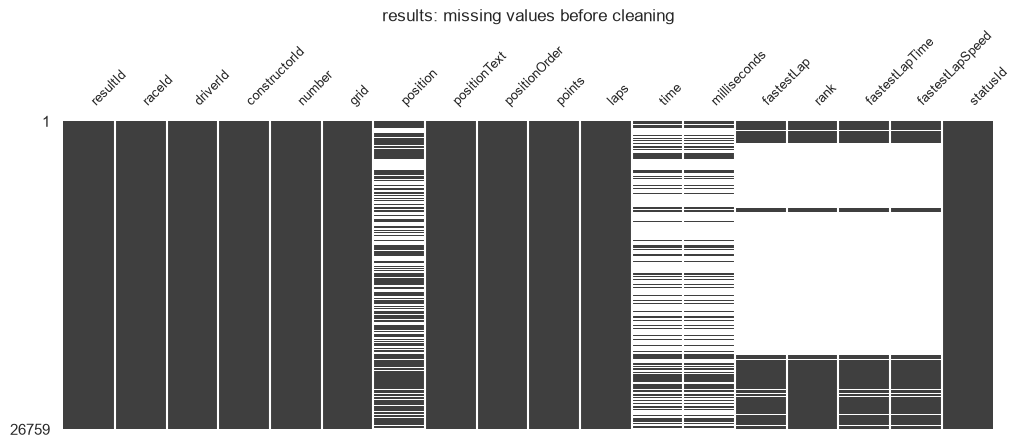

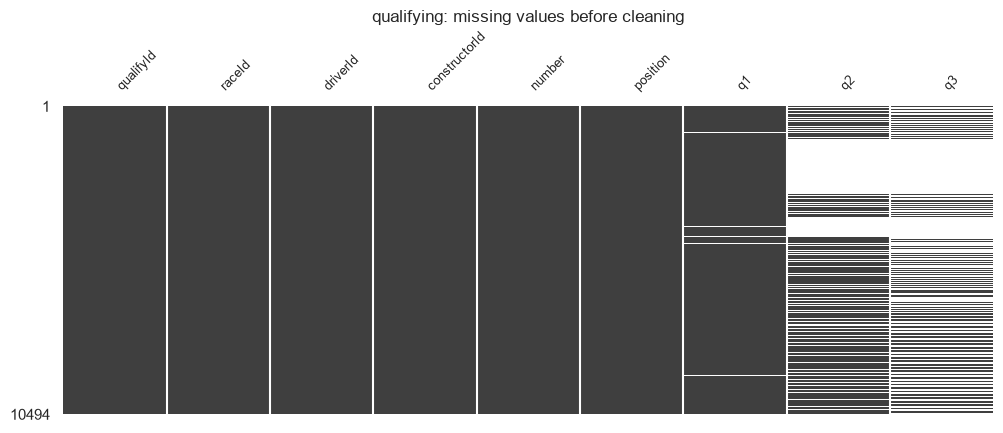

In [9]:
for t in ["results", "qualifying"]:
    msno.matrix(data[t].replace(r"\N", np.nan), figsize=(12, 4), fontsize=9, sparkline=False)
    plt.title(f"{t}: missing values before cleaning")
    save(f"fig_01_msno_before_{t}")
    plt.show()

Coverage changes over the 75 seasons. Share of missing values per season for the timing columns:

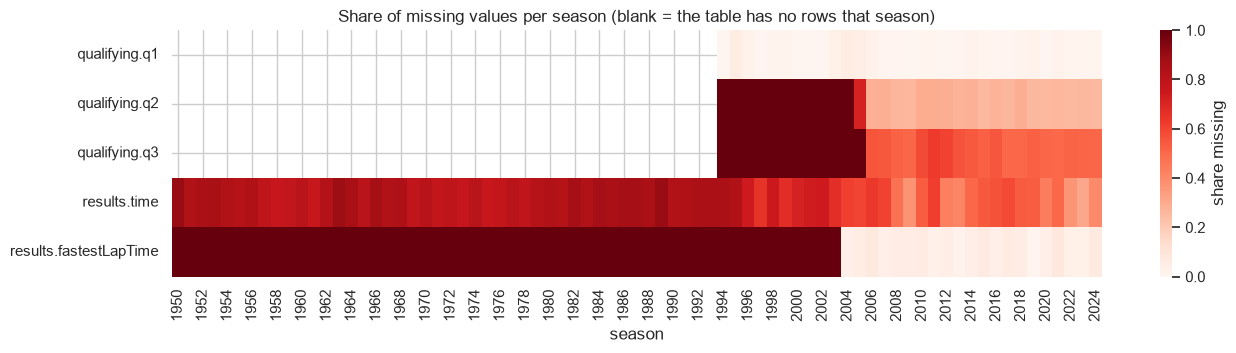

,qualifying.q1,qualifying.q2,qualifying.q3,results.time,results.fastestLapTime
raceId,,,,,
1994,0.00,1.00,1.00,0.86,1.00
2003,0.03,1.00,1.00,0.67,1.00
2014,0.02,0.28,0.55,0.51,0.04
2024,0.01,0.25,0.51,0.40,0.07


In [10]:
year = data["races"].set_index("raceId")["year"]

def is_missing(df):
    return df.isna() | df.eq(r"\N")

q, r = data["qualifying"], data["results"]
coverage = pd.concat([
    is_missing(q[["q1", "q2", "q3"]]).groupby(q["raceId"].map(year)).mean().add_prefix("qualifying."),
    is_missing(r[["time", "fastestLapTime"]]).groupby(r["raceId"].map(year)).mean().add_prefix("results."),
], axis=1).reindex(range(1950, 2025))

fig, ax = plt.subplots(figsize=(15, 3.2))
sns.heatmap(coverage.T, cmap="Reds", cbar_kws={"label": "share missing"}, ax=ax)
ax.set(title="Share of missing values per season (blank = the table has no rows that season)", xlabel="season")
save("fig_02_missing_by_season")
plt.show()
coverage.loc[[1994, 2003, 2014, 2024]].round(2)

### Inconsistent naming and spelling variations

Checking for inconsistent naming, alternative country spellings (e.g. `USA` vs `United States`), and invisible trailing spaces in categorical columns before cleaning:


In [11]:
print(data["circuits"]["country"].value_counts()[["USA", "United States"]], "\n")
nat = data["drivers"]["nationality"]
print(nat[nat.str.contains("Argentin|-|East")].value_counts().rename(index=repr))  # repr shows trailing spaces

country
USA              11
United States     1
Name: count, dtype: int64 

nationality
'Argentine'            24
'East German'           3
'American-Italian'      1
'Argentine-Italian'     1
'Argentinian '          1
Name: count, dtype: int64


### Starting grid distribution and historical field sizes (entries per race)

Next, we examine historical field sizes and grid slot assignments across eras:
- **Grid slot distribution (`grid`):** A distinct spike occurs at `0`. In the raw database, `grid = 0` is overloaded: it denotes both non-starters (who failed to qualify or withdrew) and pit-lane starters (who drove laps).
- **Entries per race across seasons:** In early decades (especially 1970s–1990s pre-qualifying eras), field sizes were dramatically larger (sometimes 30+ car entries per Grand Prix) compared to modern 20-car grids. Many drivers entered but never started.


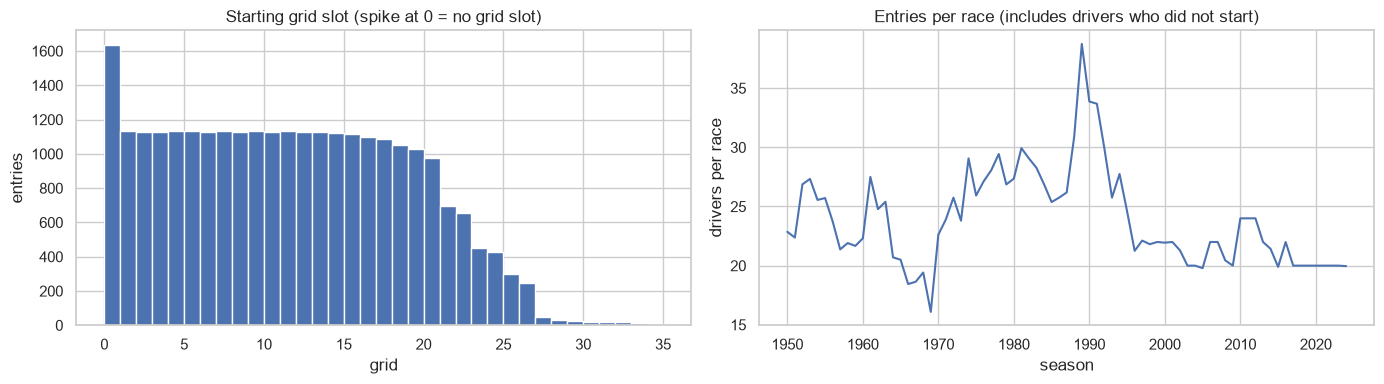

grid == 0: 1,638 entries, of which 72 still drove laps


In [12]:
entries_per_race = data["results"]["raceId"].map(year).value_counts().sort_index() / year.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(data["results"]["grid"], bins=range(0, 36))
axes[0].set(title="Starting grid slot (spike at 0 = no grid slot)", xlabel="grid", ylabel="entries")
axes[1].plot(entries_per_race.index, entries_per_race.values)
axes[1].set(title="Entries per race (includes drivers who did not start)", xlabel="season", ylabel="drivers per race")
plt.tight_layout()
save("fig_03_grid_and_entries")
plt.show()
print(f"grid == 0: {(data['results']['grid'] == 0).sum():,} entries, "
      f"of which {((data['results']['grid'] == 0) & (data['results']['laps'] > 0)).sum()} still drove laps")

**What this shows**
- `\N` is concentrated in columns that describe how a race ended (`time`, `fastestLap`, `position`). A missing finishing `position` means the driver did not finish. That is real information, so it is never filled in.
- Qualifying times exist only from 1994. `q2`/`q3` are empty before 2003 and partly empty after, because only the faster drivers reach Q2 and Q3. Qualifying times therefore cannot be a feature for most of the history.
- `grid = 0` has two meanings: drivers who never started (did not qualify or withdrew, 0 laps) and pit-lane starters (laps > 0). Cleaning separates them.
- Before the 1990s many more drivers entered per race than could start. Removing the entries that did not qualify fixes this.
- `USA` / `United States` and `Argentine` / `Argentinian ` (with a trailing space) are the same thing written differently. Cleaning unifies them.

## 5. Keys and duplicates

- **Primary key**: the column(s) that identify a row. It must be unique and never empty.
- **Foreign key**: a column pointing to another table, for example `results.driverId` → `drivers.driverId`. Every value must exist in the table it points to; a value that doesn't is called an *orphan*.

Each check stops the notebook if it fails.

In [13]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructors": ["constructorId"], "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"], "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"], "races": ["raceId"], "results": ["resultId"],
    "qualifying": ["qualifyId"], "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"], "seasons": ["year"], "sprint_results": ["resultId"],
    "status": ["statusId"],
}
pk = pd.DataFrame([{"table": t, "key": " + ".join(k), "unique": not data[t].duplicated(k).any(),
                    "no empty values": bool(data[t][k].notna().all().all())} for t, k in PRIMARY_KEYS.items()])
assert pk[["unique", "no empty values"]].all().all()
pk

,table,key,unique,no empty values
0,circuits,circuitId,True,True
1,constructors,constructorId,True,True
2,constructor_results,constructorResultsId,True,True
3,constructor_standings,constructorStandingsId,True,True
4,drivers,driverId,True,True
5,driver_standings,driverStandingsId,True,True
6,races,raceId,True,True
7,results,resultId,True,True
8,qualifying,qualifyId,True,True
9,lap_times,raceId + driverId + lap,True,True


In [14]:
FOREIGN_KEYS = [  # (table, column, table it points to); the column has the same name in both tables
    ("results", "raceId", "races"), ("results", "driverId", "drivers"), ("results", "constructorId", "constructors"),
    ("results", "statusId", "status"), ("races", "circuitId", "circuits"),
    ("qualifying", "raceId", "races"), ("qualifying", "driverId", "drivers"), ("qualifying", "constructorId", "constructors"),
    ("driver_standings", "raceId", "races"), ("driver_standings", "driverId", "drivers"),
    ("constructor_standings", "raceId", "races"), ("constructor_standings", "constructorId", "constructors"),
    ("constructor_results", "raceId", "races"), ("constructor_results", "constructorId", "constructors"),
    ("lap_times", "raceId", "races"), ("lap_times", "driverId", "drivers"),
    ("pit_stops", "raceId", "races"), ("pit_stops", "driverId", "drivers"),
    ("sprint_results", "raceId", "races"), ("sprint_results", "driverId", "drivers"),
    ("sprint_results", "constructorId", "constructors"), ("sprint_results", "statusId", "status"),
]
fk = pd.DataFrame([{"table": t, "column": c, "points to": ref, "orphans": int((~data[t][c].isin(data[ref][c])).sum())}
                   for t, c, ref in FOREIGN_KEYS])
assert fk["orphans"].eq(0).all()
print(f"all {len(fk)} foreign keys have 0 orphans")

all 22 foreign keys have 0 orphans


### Uniqueness check: Relational primary keys vs. modeling entity grain

In the relational database schema, the technical primary key for `results` is the surrogate key `resultId`.
However, for predictive modeling, our target entity (unit of analysis) is a **driver's entry in a race**, naturally identified by the composite key `(raceId, driverId)`.

In modern F1, each driver participates at most once per race. But in historical data, we must verify whether `(raceId, driverId)` is strictly unique or if duplicate entries exist:


In [15]:
KEY = ["raceId", "driverId"]
res = data["results"]
dups = res[res.duplicated(KEY, keep=False)].assign(year=lambda d: d["raceId"].map(year))
print(f"{dups.groupby(KEY).ngroups} (race, driver) pairs appear more than once ({len(dups)} rows), "
      f"all between {dups['year'].min()} and {dups['year'].max()}")
(dups.merge(data["drivers"][["driverId", "surname"]], on="driverId")
     [["year", "raceId", "surname", "grid", "laps", "positionOrder"]].sort_values(["year", "raceId", "surname"]).head(8))

85 (race, driver) pairs appear more than once (176 rows), all between 1950 and 1978


,year,raceId,surname,grid,laps,positionOrder
84,1950,835,Bettenhausen,8,30,31
88,1950,835,Bettenhausen,9,136,5
85,1950,838,Rosier,6,10,12
89,1950,838,Rosier,15,56,6
87,1950,839,Ascari,2,21,17
90,1950,839,Ascari,6,80,2
86,1950,839,Fangio,1,23,15
91,1950,839,Fangio,7,34,13


**Why duplicates exist:** These are historical **shared drives**. In the 1950s–1970s, Formula 1 regulations permitted a driver to take over a teammate's car during a race if their own car retired, or two drivers to share a car. Both stints were recorded in `results` under separate `resultId`s, causing the same `(raceId, driverId)` pair to appear twice.

**Are we changing the table's primary key?**
- In the raw relational database, `resultId` remains the unique surrogate primary key.
- But for our downstream modeling table (and in the cleaned copy `clean["results"]` created in Section 6), we cannot feed multiple rows for the same driver in the same race with conflicting outcomes.
- Therefore, in Section 6 (step 5), we resolve these duplicates by keeping only the car the driver *started* in (the row with the lowest real grid slot, known before race start).
- After this step, `(raceId, driverId)` becomes the unique composite key for `clean["results"]` and the modeling dataset.


## 6. Cleaning (on copies)

1. `\N` → NaN, trim spaces, and convert text columns whose values are all numbers into numbers.
2. Dates → `datetime`; lap times and durations (`"1:27.452"`) → seconds.
3. One spelling per value, plus a `home_country` for every driver, written the way `circuits` writes countries.
4. Drop unused columns (web links, practice/qualifying session times).
5. One row per (race, driver), using the rule from section 5.
6. Flags: entries that did not qualify, pit-lane starts, Indy 500.
7. A class for every reason a race ended (used in Q3).

Missing values are **not** filled here. Filling happens in section 10, using values learned from the training seasons only.

In [16]:
# 1. \N -> NaN, trim spaces, text columns that only contain numbers -> numbers
clean = {}
for t, df in data.items():
    df = df.replace(r"\N", np.nan)
    for c in df.select_dtypes(exclude="number").columns:
        df[c] = df[c].str.strip()
        as_number = pd.to_numeric(df[c], errors="coerce")
        if as_number.notna().sum() == df[c].notna().sum():  # nothing was lost, so the column is numeric
            df[c] = as_number
    clean[t] = df

assert not any((df == r"\N").any().any() for df in clean.values())
print(f"{sentinels['sentinels'].sum():,} \\N cells set to NaN. Columns converted from text to numbers:")
for t in TABLES:
    converted = [c for c in data[t].columns if data[t][c].dtype != clean[t][c].dtype and pd.api.types.is_numeric_dtype(clean[t][c])]
    if converted:
        print(f"  {t}: {converted}")

160,076 \N cells set to NaN. Columns converted from text to numbers:
  drivers: ['number']
  results: ['number', 'position', 'milliseconds', 'fastestLap', 'rank', 'fastestLapSpeed']
  sprint_results: ['position', 'milliseconds', 'fastestLap']


In [17]:
# 2. Dates and durations
def to_seconds(v):
    """'1:27.452' -> 87.452 and '1:34:50.616' -> 5690.616; each ':' part is worth 60x the next."""
    if pd.isna(v):
        return np.nan
    secs = 0.0
    for part in str(v).split(":"):
        secs = secs * 60 + float(part)
    return secs

clean["races"]["date"] = pd.to_datetime(clean["races"]["date"])
clean["drivers"]["dob"] = pd.to_datetime(clean["drivers"]["dob"])
for t, c in [("qualifying", "q1"), ("qualifying", "q2"), ("qualifying", "q3"), ("results", "fastestLapTime"),
             ("lap_times", "time"), ("pit_stops", "duration")]:
    clean[t][c] = clean[t][c].map(to_seconds)

# The dataset also stores lap and pit-stop times in milliseconds, so the parsing can be checked exactly
for t, c in [("lap_times", "time"), ("pit_stops", "duration")]:
    assert np.allclose(clean[t][c], clean[t]["milliseconds"] / 1000), t

pd.DataFrame({"q1 raw": data["qualifying"]["q1"].head(3), "q1 seconds": clean["qualifying"]["q1"].head(3),
              "pit stop raw": data["pit_stops"]["duration"].head(3), "pit stop seconds": clean["pit_stops"]["duration"].head(3)})

,q1 raw,q1 seconds,pit stop raw,pit stop seconds
0,1:26.572,86.572,26.898,26.898
1,1:26.103,86.103,25.021,25.021
2,1:25.664,85.664,23.426,23.426


In [ ]:
# 3. One spelling per value
clean["circuits"]["country"] = clean["circuits"]["country"].replace({"United States": "USA"})
NATIONALITY_FIX = {"Argentinian": "Argentine", "Argentine-Italian": "Argentine",
                   "American-Italian": "American", "East German": "German"}
for t in ["drivers", "constructors"]:
    clean[t]["nationality"] = clean[t]["nationality"].replace(NATIONALITY_FIX)

# Drivers have a nationality ("British"), circuits a country ("UK"): give each driver a home country in the
# circuits' spelling, so that "home race" in Q2 is a simple comparison
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "Argentine": "Argentina", "Australian": "Australia", "Austrian": "Austria",
    "Belgian": "Belgium", "Brazilian": "Brazil", "British": "UK", "Canadian": "Canada",
    "Chilean": "Chile", "Chinese": "China", "Colombian": "Colombia", "Czech": "Czech Republic",
    "Danish": "Denmark", "Dutch": "Netherlands", "Finnish": "Finland", "French": "France",
    "German": "Germany", "Hungarian": "Hungary", "Indian": "India", "Indonesian": "Indonesia",
    "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan", "Liechtensteiner": "Liechtenstein",
    "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco", "New Zealander": "New Zealand",
    "Polish": "Poland", "Portuguese": "Portugal", "Rhodesian": "Rhodesia", "Russian": "Russia",
    "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden", "Swiss": "Switzerland",
    "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
clean["drivers"]["home_country"] = clean["drivers"]["nationality"].map(NATIONALITY_TO_COUNTRY)
assert clean["drivers"]["home_country"].notna().all()

# 4. Drop columns that are never used
for t in clean:
    clean[t] = clean[t].drop(columns="url", errors="ignore")
clean["races"] = clean["races"].drop(columns=[c for c in clean["races"] if c.startswith(("fp", "quali", "sprint"))])

# 5. One row per (race, driver): lowest real grid slot first (grid 0 = no slot, sorted last), then the better finish
r = clean["results"]
r = r.assign(slot=r["grid"].replace(0, np.nan)).sort_values(["slot", "positionOrder"], na_position="last")
r = r.drop_duplicates(KEY).drop(columns="slot").sort_index()
assert not r.duplicated(KEY).any()
print(f"results: {len(clean['results']):,} -> {len(r):,} rows (one per race and driver)")

# 6. Flags. A pit-lane starter gets the slot behind the last car on the grid
r = r.merge(clean["races"][["raceId", "year", "name"]], on="raceId")
status_name = r["statusId"].map(clean["status"].set_index("statusId")["status"])
no_slot = (r["grid"] == 0) & (r["laps"] == 0)       # no grid slot and no lap driven
# Only entries that did not qualify are removed. Drivers who qualified (or withdrew) but did not start stay in
r["not_qualified"] = no_slot & status_name.isin(["Did not qualify", "Did not prequalify"])
r["pitlane_start"] = (r["grid"] == 0) & (r["laps"] > 0)
r["grid_eff"] = r["grid"].where(r["grid"] > 0, r.groupby("raceId")["grid"].transform("max") + 1)
r["is_indy500"] = r["name"].str.contains("Indianapolis") & (r["year"] <= 1960)  # US oval, counted 1950-60
print(f"not qualified (removed): {r['not_qualified'].sum():,} | did not start but kept: {(no_slot & ~r['not_qualified']).sum():,} | "
      f"pit-lane starts: {r['pitlane_start'].sum()} | "
      f"Indy 500 rows: {r['is_indy500'].sum()}")

In [19]:
# 7. Why each race ended: Categorizing race outcomes for Q3.
# The raw status table contains over 130 specific statuses (Engine, Gearbox, Electrical, Suspension, etc.).
# Rather than listing ~80 individual mechanical failure terms, we define the non-mechanical groups explicitly;
# any retirement status not matching finished, accident, driver, regulatory, or other defaults to
# "mechanical" via the fallback in status_class(s).
STATUS_GROUPS = {
    "finished": {"Finished"} | {s for s in clean["status"]["status"] if s.startswith("+")},  # "+1 Lap", ...
    "accident": {"Accident", "Collision", "Collision damage", "Spun off", "Fatal accident", "Damage", "Debris"},
    "driver": {"Driver unwell", "Illness", "Injured", "Injury", "Eye injury", "Physical", "Stalled"},
    "regulatory": {"Disqualified", "Excluded", "Underweight", "107% Rule", "Did not qualify", "Did not prequalify",
                   "Withdrew", "Not restarted", "Safety concerns", "Safety", "Seat", "Driver Seat", "Not classified"},
    "other": {"Refuelling"},
}

def status_class(s):
    """Categorize status string. If not in STATUS_GROUPS, defaults to 'mechanical'."""
    return next((g for g, names in STATUS_GROUPS.items() if s in names), "mechanical")

r = r.merge(clean["status"], on="statusId", how="left")
r["status_class"] = r["status"].map(status_class)
clean["results"] = r
print(r["status_class"].value_counts().to_string(), "\n")
print("most common statuses counted as mechanical:",
      r.loc[r["status_class"] == "mechanical", "status"].value_counts().head(12).index.tolist())

status_class
finished      15115
mechanical     6770
accident       2771
regulatory     1944
driver           67
other             1 

most common statuses counted as mechanical: ['Engine', 'Gearbox', 'Suspension', 'Transmission', 'Electrical', 'Brakes', 'Clutch', 'Fuel system', 'Turbo', 'Hydraulics', 'Overheating', 'Ignition']


### The data after cleaning

In [ ]:
msno.matrix(clean["results"][data["results"].columns], figsize=(12, 4), fontsize=9, sparkline=False)
plt.title("results: missing values after cleaning (\\N is now real NaN)")
save("fig_04_msno_after_results")
plt.show()

entries = clean["results"][~clean["results"]["not_qualified"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(entries_per_race.index, entries_per_race.values, label="before: all entries")
axes[0].plot(entries.groupby("year").size() / year.value_counts().sort_index(), label="after: qualified entries")
axes[0].set(title="Drivers per race, before and after removing entries that did not qualify", xlabel="season")
axes[0].legend()
axes[1].hist(clean["qualifying"]["q1"].dropna().clip(upper=150), bins=60)
axes[1].set(title="Q1 lap time after parsing (seconds)", xlabel="seconds")
plt.tight_layout()
save("fig_05_after_cleaning")
plt.show()

pd.DataFrame({"type before": data["results"].dtypes.astype(str),
              "type after": clean["results"][data["results"].columns].dtypes.astype(str)})

## 7. Target and pre-race cutoff

**Target:** `podium = 1` if `positionOrder <= 3`, else 0. Every driver who qualified is kept, including the few who did not start the race (they never finish on the podium). Only entries that did not qualify are removed.

**Cutoff:** the prediction is made after qualifying, before the start.

| Allowed (known before the start) | Not allowed (only known after the race) |
|---|---|
| `grid` (qualifying result after penalties) | `position`, `positionText`, `positionOrder`, `points` |
| driver, team, circuit identity | `laps`, `time`, `milliseconds`, `statusId` |
| championship standings **after the previous round** | `fastestLap`, `rank`, `fastestLapTime`, `fastestLapSpeed` |
| results of **earlier** races (history, form) | this race's `lap_times`, `pit_stops`, and standings after this race |

**Handling of Sprint Races:**
- **Primary historical model:** Sprint results are excluded. Sprint races were only introduced in 2021 and only take place at a few selected race weekends per season (3 to 6 rounds). Across the entire 1950–2024 history, over 99% of races had no sprint, and ~96% of training seasons (1950–2020) entirely predate the concept. Including sprints in the primary historical model would cause massive structural missingness.
- **Secondary / improved modern-era model:** On sprint weekends, the ~100 km sprint race is held on Saturday *before* Sunday's main Grand Prix. It provides direct, real-world data on actual race pace, tire degradation, and wheel-to-wheel race performance under current weekend conditions. For a secondary model specialized on the modern era (2021+), incorporating sprint finishing positions and lap pace would serve as a powerful, high-signal pre-race feature.

In [ ]:
entries = entries.assign(podium=(entries["positionOrder"] <= 3).astype(int))
print(f"podium rate: {entries['podium'].mean():.1%} of entries ({entries['podium'].sum():,} of {len(entries):,})")

by_year = entries.groupby("year")
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(by_year["podium"].mean(), label="podium rate")
ax.plot(3 / by_year.size().div(by_year["raceId"].nunique()), ls="--", label="3 / average starters per race")
ax.set(title="Podium rate per season", xlabel="season", ylabel="share of starts")
ax.legend()
save("fig_06_podium_rate")
plt.show()

- Every driver who qualified is counted, including the few who did not start: 13.3% of entries end on the podium, so the classes are imbalanced. A model that always says "no podium" would be about 87% accurate and useless, which is why **PR-AUC**, not accuracy, is the primary metric (secondary: ROC-AUC and F1 at a threshold chosen on validation).
- The rate follows 3 ÷ (starters per race) (dashed line), so it is lower in the large-field 1950s–80s (≈10%) than today (≈15%). This era shift is one reason the data is split **by season**: train on old seasons, test on the newest.
- The only gaps between the two lines are 8 races in 1951–1957 with shared drives: either a podium car is credited to several drivers, or the dropped duplicate row (section 5) held the podium.

## 8. Data-engineering questions

Each answer joins several tables and checks after every join that the number of rows did not change (a join must not duplicate rows).
Rates come with a **95% Wilson interval**, a range that the true rate is very likely to fall in. It stays sensible for small counts, such as a circuit with only 12 front-row starts.

In [22]:
def wilson(k, n, z=1.96):
    """Rate k/n with its 95% Wilson interval. Returns (rate, low, high); works on arrays."""
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z / (1 + z**2 / n) * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
    return p, centre - half, centre + half

### 8.1 Q1: Which circuits convert a front-row start into a podium most often, and did that change from 2014?

- **Front row** = grid slot 1 or 2.
- `grid` is used rather than the qualifying position: grid is where the car actually starts (after penalties), and it exists for every race since 1950. Qualifying positions exist only from 1994.
- **Conversion rate** = front-row starters who finished on the podium ÷ front-row starters, before 2014 vs 2014+ (the turbo-hybrid era).
- Only circuits with **at least 10 front-row starts (5 races) in each era** are ranked. A circuit used once has 2 front-row starts, so its rate can only be 0%, 50% or 100%.

In [23]:
q1 = (clean["results"]
      .merge(clean["races"][["raceId", "circuitId"]], on="raceId")
      .merge(clean["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"}), on="circuitId"))
assert len(q1) == len(clean["results"])
q1 = q1[q1["grid"].isin([1, 2])].assign(podium=lambda d: d["positionOrder"] <= 3,
                                        era=lambda d: np.where(d["year"] >= 2014, "2014+", "pre-2014"))

overall_q1 = q1.groupby("era")["podium"].agg(["sum", "count"]).loc[["pre-2014", "2014+"]]
overall_q1["rate"], overall_q1["low"], overall_q1["high"] = wilson(overall_q1["sum"], overall_q1["count"])
overall_q1.round(3)

,sum,count,rate,low,high
era,,,,,
pre-2014,1002,1805,0.555,0.532,0.578
2014+,345,454,0.760,0.719,0.797


**Which circuits can be compared between the eras?** The dataset has 77 circuits, but most were used in only one era: old tracks dropped long before 2014, or new tracks added after it. Only circuits raced in **both** eras can show whether their ranking changed, and of those, only circuits with at least 5 races in each era get a rate that is not mostly luck:

In [24]:
races_per_era = q1.groupby(["circuit", "era"])["raceId"].nunique().unstack(fill_value=0)
both = (races_per_era > 0).all(axis=1)
funnel = pd.Series({
    "circuits in the dataset": len(clean["circuits"]),
    "raced only before 2014": int(((races_per_era["pre-2014"] > 0) & (races_per_era["2014+"] == 0)).sum()),
    "raced only from 2014": int(((races_per_era["pre-2014"] == 0) & (races_per_era["2014+"] > 0)).sum()),
    "raced in both eras": int(both.sum()),
    "in both eras but fewer than 5 races in one": int((both & (races_per_era < 5).any(axis=1)).sum()),
    "ranked (at least 5 races in both eras)": int((races_per_era >= 5).all(axis=1).sum()),
}, name="circuits")
print("in both eras but too few races:", sorted(races_per_era.index[both & (races_per_era < 5).any(axis=1)]))
funnel.to_frame()

in both eras but too few races: ['Autodromo Enzo e Dino Ferrari', 'Circuit Park Zandvoort', 'Circuit Paul Ricard', 'Circuit of the Americas', 'Hockenheimring', 'Istanbul Park', 'Nürburgring', 'Sepang International Circuit']


,circuits
circuits in the dataset,77
raced only before 2014,45
raced only from 2014,8
raced in both eras,24
in both eras but fewer than 5 races in one,8
ranked (at least 5 races in both eras),16


circuits ranked for each minimum: {5: 21, 10: 16, 15: 13, 20: 7}


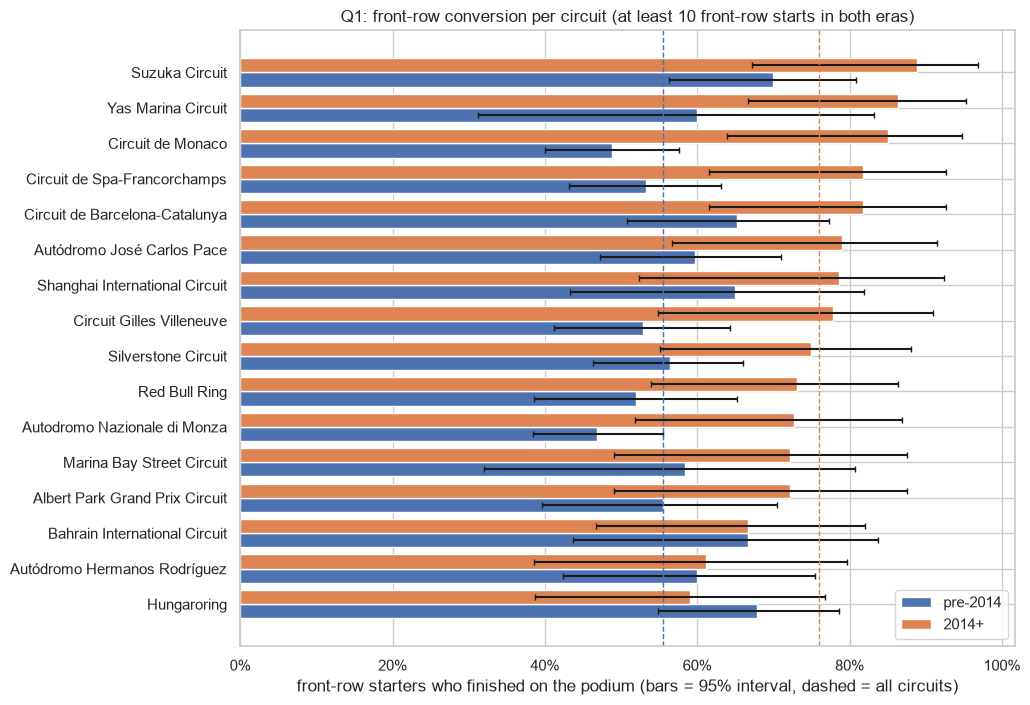

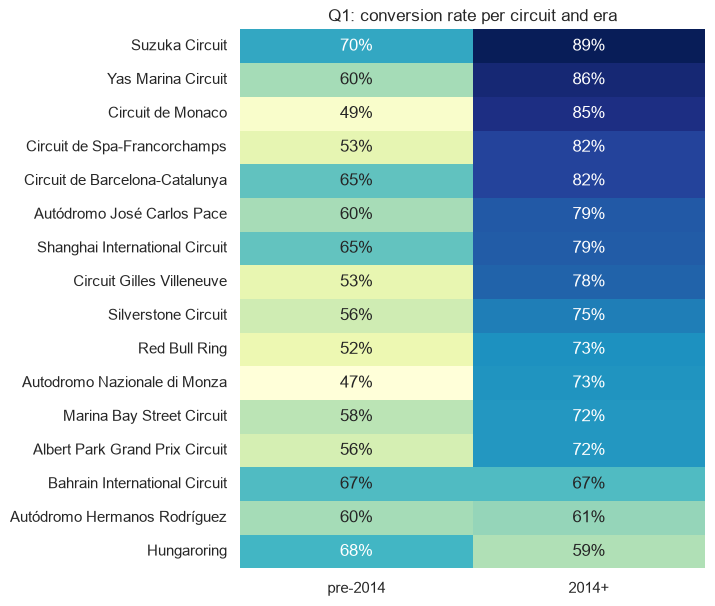

rank correlation between the eras (Spearman): -0.03   (1 = same order, 0 = unrelated order)


In [25]:
K_MIN = 10
circ = q1.groupby(["circuit", "era"])["podium"].agg(["sum", "count"]).reset_index()
starts_in_worse_era = circ.pivot(index="circuit", columns="era", values="count").fillna(0).min(axis=1)
print("circuits ranked for each minimum:", {k: int((starts_in_worse_era >= k).sum()) for k in (5, 10, 15, 20)})
circ = circ[circ["circuit"].isin(starts_in_worse_era[starts_in_worse_era >= K_MIN].index)].copy()
circ["rate"], circ["low"], circ["high"] = wilson(circ["sum"], circ["count"])
rates = circ.pivot(index="circuit", columns="era", values="rate")[["pre-2014", "2014+"]].sort_values("2014+")

fig, ax = plt.subplots(figsize=(10, 8))
y = np.arange(len(rates))
for i, era in enumerate(["pre-2014", "2014+"]):
    d = circ[circ["era"] == era].set_index("circuit").loc[rates.index]
    ax.barh(y + (i - 0.5) * 0.4, d["rate"], height=0.4, color=f"C{i}", label=era,
            xerr=[d["rate"] - d["low"], d["high"] - d["rate"]], capsize=2)
    ax.axvline(overall_q1.loc[era, "rate"], color=f"C{i}", ls="--", lw=1)
ax.set_yticks(y, rates.index)
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set(xlabel="front-row starters who finished on the podium (bars = 95% interval, dashed = all circuits)",
       title=f"Q1: front-row conversion per circuit (at least {K_MIN} front-row starts in both eras)")
ax.legend(loc="lower right")
save("fig_07_q1_circuits")
plt.show()

fig, ax = plt.subplots(figsize=(6, 7))
sns.heatmap(rates.iloc[::-1], annot=True, fmt=".0%", cmap="YlGnBu", cbar=False, ax=ax)
ax.set(title="Q1: conversion rate per circuit and era", xlabel="", ylabel="")
save("fig_08_q1_heatmap")
plt.show()

rho = rates["pre-2014"].corr(rates["2014+"], method="spearman")
print(f"rank correlation between the eras (Spearman): {rho:.2f}   (1 = same order, 0 = unrelated order)")

**Answer Q1:** A front-row start converts much more often in the hybrid era: **55.5% before 2014 → 76.0% from 2014** (95% intervals 53–58% and 72–80%; they do not overlap).
The best circuits since 2014 are Suzuka, Yas Marina and Monaco (heatmap). The circuit ranking is **not stable** between the eras (rank correlation −0.03, about 0): which track rewards a front-row start depends on the era, not on the track alone.

### 8.2 Q2: Do drivers podium more often at home, for the same starting position?

A **home race** is a race at a circuit in the driver's home country (cleaning step 3). Home drivers might simply qualify better, so podium rates are compared **within starting-position groups** (pole, 2–3, 4–6, 7–10, 11+). The difference inside each group is averaged, weighted by the number of home starts.
A logistic regression model then estimates the home effect while holding the starting group and era fixed. Its result is reported as an **odds ratio**: 1 means no effect, above 1 means home helps.
The Indy 500 is excluded: it was an American oval race that regular F1 drivers rarely entered.

In [ ]:
entries = clean["results"].query("~not_qualified and ~is_indy500")
q2 = (entries
      .merge(clean["drivers"][["driverId", "home_country"]], on="driverId")
      .merge(clean["races"][["raceId", "circuitId"]], on="raceId")
      .merge(clean["circuits"][["circuitId", "country"]], on="circuitId"))
assert len(q2) == len(entries)
q2["home"] = (q2["home_country"] == q2["country"]).astype(int)
q2["podium"] = (q2["positionOrder"] <= 3).astype(int)
q2["start"] = pd.cut(q2["grid_eff"], [0, 1, 3, 6, 10, 100], labels=["pole", "2-3", "4-6", "7-10", "11+"])
print(f"{len(q2):,} starts, {q2['home'].sum():,} of them at home ({q2['home'].mean():.1%})")

g = q2.groupby(["start", "home"], observed=True)["podium"].agg(["sum", "count"]).unstack("home")
strat = pd.DataFrame({"away rate": g["sum"][0] / g["count"][0], "home rate": g["sum"][1] / g["count"][1],
                      "home starts": g["count"][1], "away starts": g["count"][0]})
strat["home - away"] = strat["home rate"] - strat["away rate"]
weighted_gap = (strat["home - away"] * strat["home starts"]).sum() / strat["home starts"].sum()
print(f"weighted home - away difference: {weighted_gap * 100:+.2f} percentage points")
strat.round(3)

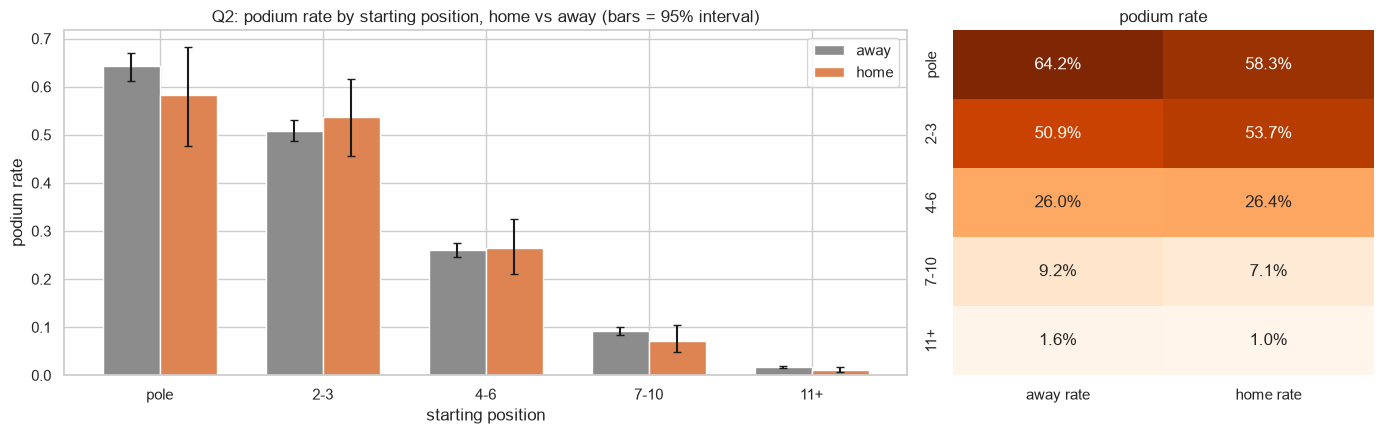

home odds ratio (same starting group and era): 0.915


In [27]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
x = np.arange(len(strat))
for i, (side, colour) in enumerate([(0, "C7"), (1, "C1")]):
    rate, low, high = wilson(g["sum"][side], g["count"][side])
    ax1.bar(x + (i - 0.5) * 0.35, rate, width=0.35, color=colour, label=["away", "home"][side],
            yerr=[rate - low, high - rate], capsize=3)
ax1.set_xticks(x, strat.index)
ax1.set(title="Q2: podium rate by starting position, home vs away (bars = 95% interval)",
        xlabel="starting position", ylabel="podium rate")
ax1.legend()
sns.heatmap(strat[["away rate", "home rate"]], annot=True, fmt=".1%", cmap="Oranges", cbar=False, ax=ax2)
ax2.set(title="podium rate", ylabel="")
plt.tight_layout()
save("fig_09_q2_home")
plt.show()

q2["era"] = pd.cut(q2["year"], [1949, 1979, 2013, 2024], labels=["pre-1980", "1980-2013", "2014+"])
X_q2 = pd.get_dummies(q2[["home", "start", "era"]], drop_first=True)
lr_q2 = LogisticRegression(C=1e5, max_iter=1000).fit(X_q2, q2["podium"])  # large C = practically no regularisation
print(f"home odds ratio (same starting group and era): {np.exp(lr_q2.coef_[0][0]):.3f}")

**Answer Q2:** **No home advantage.** Starting from the same position, home drivers are 0.70 percentage points *less* likely to finish on the podium. The odds ratio is 0.912 (below 1). In every starting group the home and away 95% intervals overlap, so the small negative gap cannot be told apart from no effect.

### 8.3 Q3: Which constructors have the highest mechanical-retirement rate, 2014–2021 vs 2022–2024?

**Mechanical retirement rate** = race starts that ended because a part of the car failed ÷ race starts, for each team (`constructors.name`). Unclear reasons (punctures, wing failures, plain "Retired") count as mechanical (cleaning step 7); crashes, driver problems and rule decisions do not.
The two periods are the turbo-hybrid engine rules (2014–2021) and the new car rules (2022–2024). They differ in length, so rates are compared, never counts.

In [ ]:
q3 = (clean["results"].query("~not_qualified and 2014 <= year <= 2024")
      .merge(clean["constructors"][["constructorId", "name"]].rename(columns={"name": "team"}), on="constructorId"))
q3["period"] = np.where(q3["year"] <= 2021, "2014-2021", "2022-2024")
q3["mechanical"] = q3["status_class"] == "mechanical"

overall_q3 = q3.groupby("period")["mechanical"].agg(["sum", "count"])
overall_q3["rate"], overall_q3["low"], overall_q3["high"] = wilson(overall_q3["sum"], overall_q3["count"])
team = q3.groupby(["period", "team"])["mechanical"].agg(["sum", "count"]).reset_index()
team["rate"], team["low"], team["high"] = wilson(team["sum"], team["count"])
print("fewest starts of any team:", team.groupby("period")["count"].min().to_dict())
overall_q3.round(3)

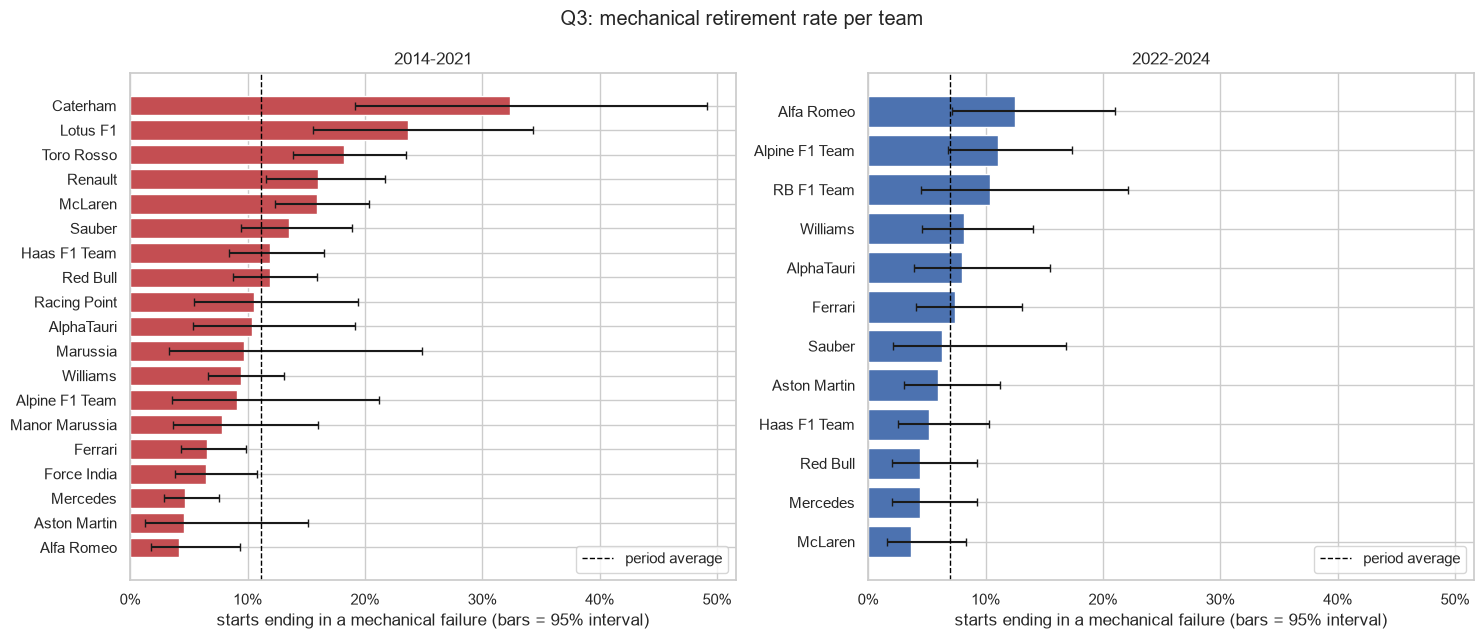

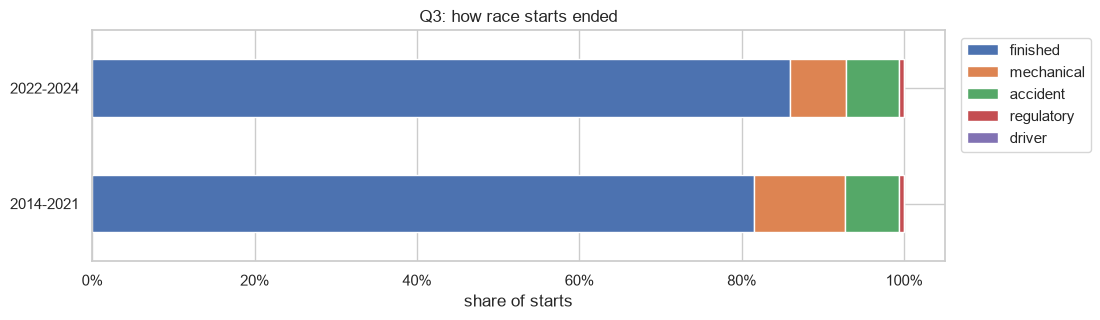

,period,team,count,sum,rate
4,2014-2021,Caterham,34,11,0.324
8,2014-2021,Lotus F1,76,18,0.237
17,2014-2021,Toro Rosso,242,44,0.182
19,2022-2024,Alfa Romeo,88,11,0.125
21,2022-2024,Alpine F1 Team,136,15,0.110
27,2022-2024,RB F1 Team,48,5,0.104


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True)
for ax, (period, d), colour in zip(axes, team.groupby("period"), ["C3", "C0"]):
    d = d.sort_values("rate")
    ax.barh(d["team"], d["rate"], color=colour, xerr=[d["rate"] - d["low"], d["high"] - d["rate"]], capsize=3)
    ax.axvline(overall_q3.loc[period, "rate"], color="black", ls="--", lw=1, label="period average")
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.set(title=period, xlabel="starts ending in a mechanical failure (bars = 95% interval)")
    ax.legend(loc="lower right")
fig.suptitle("Q3: mechanical retirement rate per team")
plt.tight_layout()
save("fig_10_q3_teams")
plt.show()

outcome = q3.groupby("period")["status_class"].value_counts(normalize=True).unstack()
ax = outcome[["finished", "mechanical", "accident", "regulatory", "driver"]].plot.barh(stacked=True, figsize=(11, 3))
ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set(title="Q3: how race starts ended", xlabel="share of starts", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
save("fig_11_q3_outcomes")
plt.show()

team.sort_values("rate", ascending=False).groupby("period").head(3)[["period", "team", "count", "sum", "rate"]].round(3)

**Answer Q3:** Cars became more reliable: **11.3% (2014–2021) → 7.0% (2022–2024)** (95% intervals 10.2–12.4% and 5.7–8.5%) of starts ended with a mechanical failure.
The least reliable teams were **Caterham (32%)**, Lotus F1 (24%) and Toro Rosso (18%) in 2014–2021, and **Alfa Romeo (12.5%)**, Alpine (11%) and RB (10%) in 2022–2024. Caterham's rate rests on only 34 starts, so its interval is wide.

## 9. Modeling table and candidate features

One row per driver who **qualified** for a race (including the few who did not start it), 1950–2024, without the Indy 500.
The split is **by season**, so the model is always scored on years it has never seen:

| Part | Seasons | Used for |
|---|---|---|
| train | 1950–2017 | fitting models, imputer and scaler |
| validation | 2018–2021 | choosing features, settings and thresholds |
| test | 2022–2024 | the final score, used once (section 14) |

A random split (e.g. standard `train_test_split`) would put drivers from the same race on both sides and train on the future, which makes scores look better than they are.

In [ ]:
mt = clean["results"].query("~not_qualified and ~is_indy500").copy()
mt["podium"] = (mt["positionOrder"] <= 3).astype(int)
mt["grid"] = mt["grid_eff"]                                              # no slot (pit lane, did not start) = behind the last car
mt["field_size"] = mt.groupby("raceId")["raceId"].transform("size")    # cars in the race
mt["grid_rel"] = mt["grid"] / mt["field_size"]                         # 10th of 20 is not 10th of 34
mt["split"] = pd.cut(mt["year"], [1949, 2017, 2021, 2024], labels=["train", "val", "test"])
assert not mt.duplicated(KEY).any()

split_sizes = mt.groupby("split", observed=True)["podium"].agg(rows="size", podiums="sum", podium_rate="mean")
split_sizes.round(3)

**Candidate features.** Each one uses only information from **before** the race being predicted:

| Group | Features | Meaning |
|---|---|---|
| grid | `grid` | starting slot |
| field size | `field_size`, `grid_rel` | cars in the race, grid ÷ cars in the race |
| driver standings | `drv_pos`, `drv_pts_share`, `drv_wins` | championship position, points ÷ leader's points, wins, **after the previous round** |
| team standings | `con_pos`, `con_pts_share`, `con_wins` | the same for the team |
| recent form | `drv_podium_last5`, `con_podium_last5` | podium share in the last 5 races |

Round 1 has no previous round, and rookies have no history, so these values can be missing. Section 10 fills them.

Driver and team identity enter only through these features. One-hot encoding the ~900 driver IDs would add hundreds of mostly empty columns, and many test drivers never appear in training.

In [31]:
# Races in date order, and each race's previous round in the same season
rc = clean["races"].sort_values(["year", "round"]).reset_index(drop=True)
rc["race_idx"] = rc.index
rc["prev_raceId"] = rc.groupby("year")["raceId"].shift(1).astype("Int64")
mt = mt.merge(rc[["raceId", "race_idx", "prev_raceId"]], on="raceId", validate="many_to_one")

def standings_before(table, key, prefix):
    """Standings after the previous round (what everyone knew before this race)."""
    s = clean[table].rename(columns={"raceId": "prev_raceId", "position": f"{prefix}_pos", "wins": f"{prefix}_wins"})
    leader = s.groupby("prev_raceId")["points"].transform("max")
    s[f"{prefix}_pts_share"] = (s["points"] / leader).where(leader > 0, 0.0)
    return s[["prev_raceId", key, f"{prefix}_pos", f"{prefix}_pts_share", f"{prefix}_wins"]]

mt = mt.merge(standings_before("driver_standings", "driverId", "drv"), on=["prev_raceId", "driverId"],
              how="left", validate="many_to_one")
mt = mt.merge(standings_before("constructor_standings", "constructorId", "con"), on=["prev_raceId", "constructorId"],
              how="left", validate="many_to_one")

def last5_rate(key):
    """Podium share over the previous 5 races (for a team: share of its cars)."""
    g = mt.groupby([key, "race_idx"])["podium"].mean().reset_index()
    g["rate"] = g.groupby(key)["podium"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    return mt[[key, "race_idx"]].merge(g, on=[key, "race_idx"], how="left")["rate"].to_numpy()

mt["drv_podium_last5"], mt["con_podium_last5"] = last5_rate("driverId"), last5_rate("constructorId")

In [32]:
# Leakage check: recompute 150 random rows the slow way, from earlier races only
rng = np.random.default_rng(SEED)
for i in rng.choice(len(mt), 150, replace=False):
    row = mt.iloc[i]
    for key, col in [("driverId", "drv_podium_last5"), ("constructorId", "con_podium_last5")]:
        past = mt[(mt[key] == row[key]) & (mt["race_idx"] < row["race_idx"])]
        form = past.groupby("race_idx")["podium"].mean().tail(5).mean() if len(past) else np.nan
        assert np.isclose(row[col], form, equal_nan=True)
print("recent form uses earlier races only")

GROUPS = {
    "grid": ["grid"],
    "field size": ["field_size", "grid_rel"],
    "driver standings": ["drv_pos", "drv_pts_share", "drv_wins"],
    "team standings": ["con_pos", "con_pts_share", "con_wins"],
    "recent form": ["drv_podium_last5", "con_podium_last5"],
}
CANDIDATES = sum(GROUPS.values(), [])
print("share of rows with a missing value:")
mt.groupby("split", observed=True)[CANDIDATES].agg(lambda s: s.isna().mean()).T.round(3)

recent form uses earlier races only
share of rows with a missing value:


split,train,val,test
grid,0.000,0.000,0.000
field_size,0.000,0.000,0.000
grid_rel,0.000,0.000,0.000
drv_pos,0.128,0.052,0.050
drv_pts_share,0.128,0.052,0.050
drv_wins,0.128,0.052,0.050
con_pos,0.128,0.049,0.044
con_pts_share,0.128,0.049,0.044
con_wins,0.128,0.049,0.044
drv_podium_last5,0.031,0.007,0.006


## 10. Preprocessing

1. **Impute**: fill missing values with the **median** of the training rows (`SimpleImputer`). The median is robust to skewed columns such as wins.
2. **Scale**: `StandardScaler` gives every feature mean 0 and standard deviation 1, so a feature with large numbers (grid 1–34) does not dominate small ones (rates 0–0.6). Scaling matters for logistic regression and the neural network. The random forest doesn't care, but every model gets the same inputs so the comparison is fair.

Missing values in validation and test rows stay as they are in the data and are filled with the training medians; no row is dropped for having a missing value.

Both steps are **fit on the training seasons only** and then applied unchanged to validation and test. `prepare` does this for any list of columns.

In [33]:
tr, va, te = (mt[mt["split"] == s] for s in ["train", "val", "test"])
y_train, y_val, y_test = tr["podium"], va["podium"], te["podium"]

def prepare(cols, pipe=None, fit_on=None):
    """Fit imputer + scaler on the train rows (or `fit_on`) and return scaled train / val / test."""
    pipe = pipe or make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    pipe.fit((tr if fit_on is None else fit_on)[cols].astype(float))
    return [pd.DataFrame(pipe.transform(d[cols].astype(float)), columns=cols, index=d.index) for d in (tr, va, te)], pipe

## 11. Feature selection

Two kinds of evidence:
1. **Exploratory (11.1):** does each candidate, on its own, separate podiums from the rest? (univariate plots and correlations)
2. **Empirical (11.2):** start from `grid`, add one group at a time, and keep a group only if the models improve on validation.

The test seasons are not used here.

### 11.1 Does each candidate separate podiums from the rest?

The training rows are cut into five equal-sized groups by the candidate's value, and the podium rate of each group is plotted (binned conversion rate analysis). Grey = no value. Flat bars mean no signal.

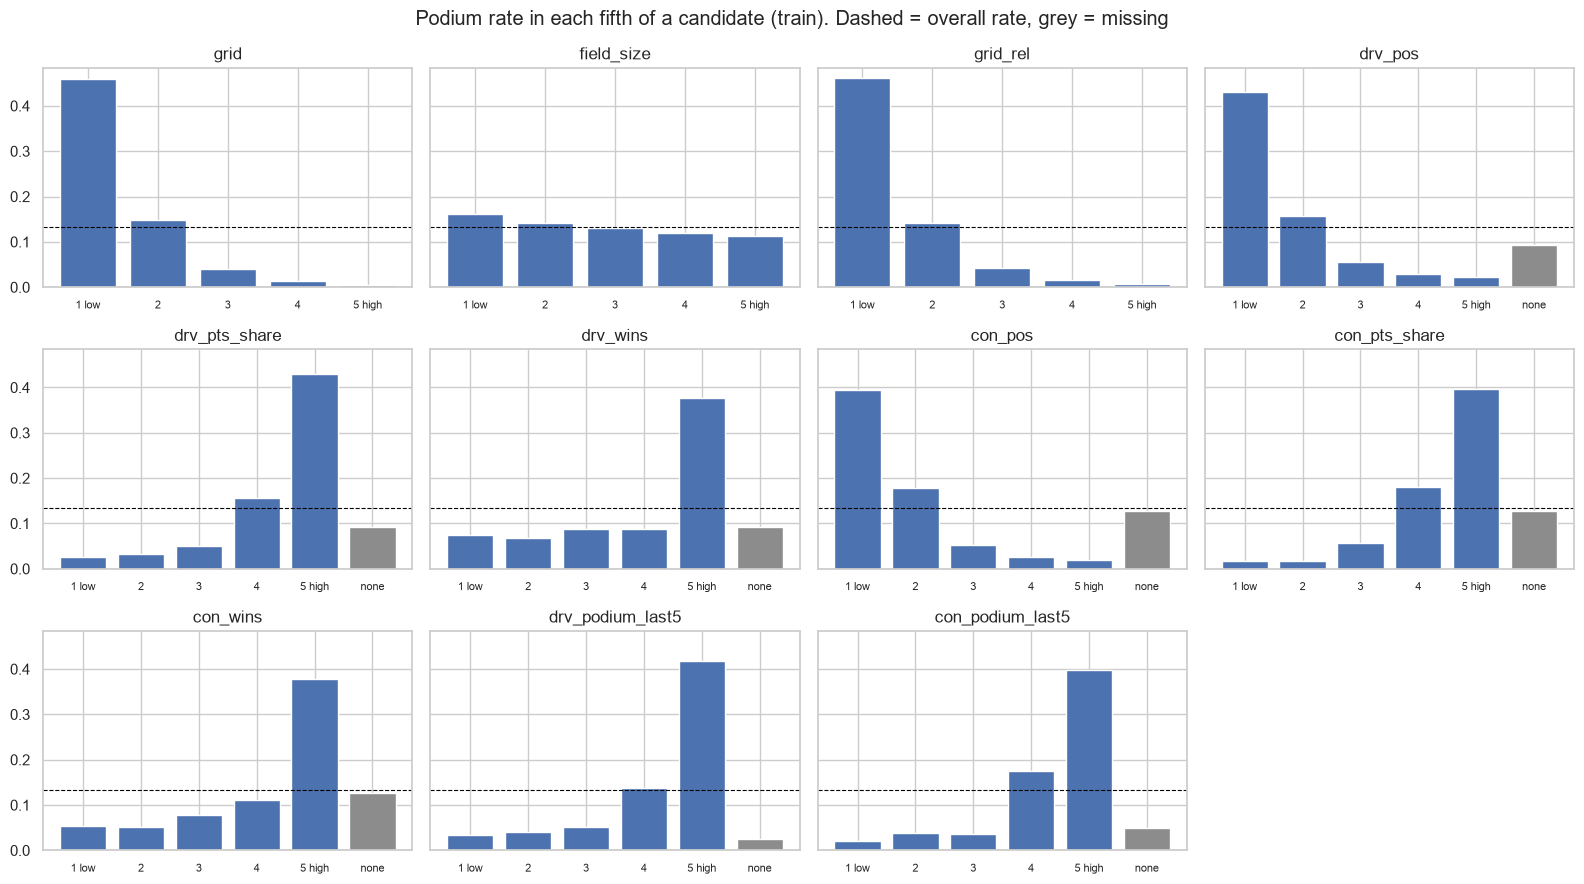

In [34]:
FIFTHS = ["1 low", "2", "3", "4", "5 high"]
PRIOR = tr["podium"].mean()   # overall train podium rate (dashed line)
fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharey=True)
for ax, col in zip(axes.ravel(), CANDIDATES):
    x = tr[col].astype(float)
    fifth = pd.qcut(x.rank(method="first"), 5, labels=FIFTHS).astype(str).where(x.notna(), "none")
    rate = tr.groupby(fifth)["podium"].mean().reindex(FIFTHS + ["none"]).dropna()
    ax.bar(rate.index, rate.values, color=["C7" if g == "none" else "C0" for g in rate.index])
    ax.axhline(PRIOR, color="black", lw=0.8, ls="--")
    ax.set_title(col)
    ax.tick_params(axis="x", labelsize=8)
for ax in axes.ravel()[len(CANDIDATES):]:
    ax.axis("off")
fig.suptitle("Podium rate in each fifth of a candidate (train). Dashed = overall rate, grey = missing")
plt.tight_layout()
save("fig_12_feature_fifths")
plt.show()

Correlation with the target. **Spearman** is used instead of Pearson because the relations above are not straight lines: for `grid`, the podium rate drops steeply over the first slots and then flattens. The heatmap also shows which candidates repeat each other.

grid               -0.449
grid_rel           -0.444
drv_podium_last5    0.434
con_podium_last5    0.414
drv_wins            0.404
con_wins            0.402
drv_pts_share       0.400
drv_pos            -0.400
con_pts_share       0.395
con_pos            -0.385
field_size         -0.053


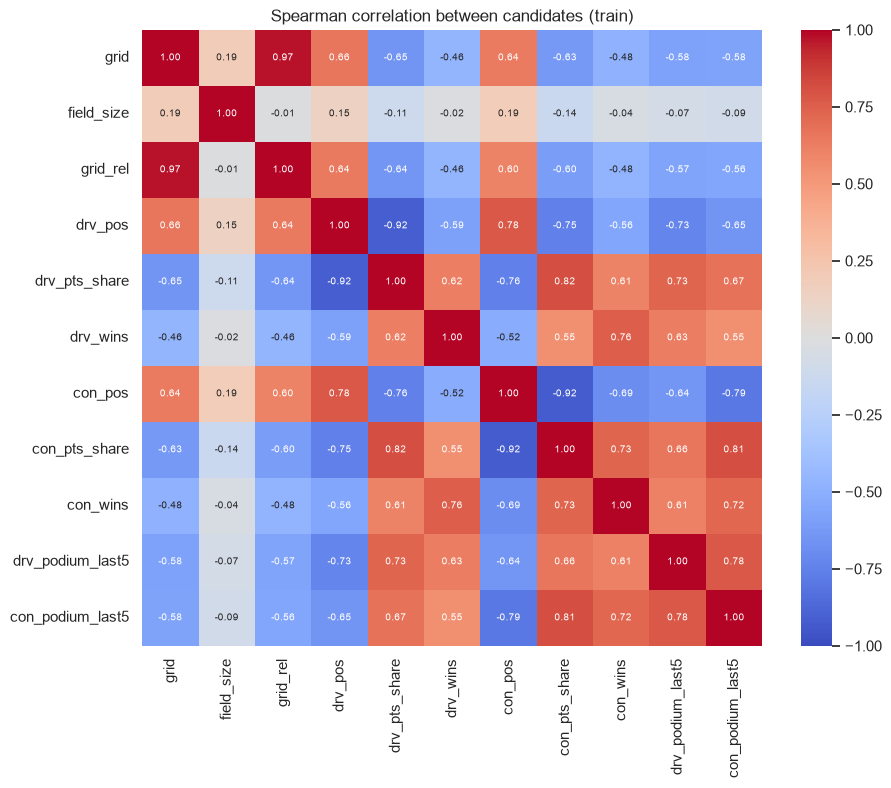

In [35]:
rho = tr[CANDIDATES].astype(float).corrwith(tr["podium"], method="spearman")
print(rho.reindex(rho.abs().sort_values(ascending=False).index).round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(tr[CANDIDATES].astype(float).corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation between candidates (train)")
save("fig_13_feature_corr")
plt.show()

**What the plots and correlations say**
- **Strong on their own:** `grid` / `grid_rel`, recent form, and the driver and team standings. Their bars climb (or fall) steeply across the fifths, and their Spearman correlations with podium are 0.38–0.45 in size.
- **Weak:** `field_size` (−0.05). The number of starters alone says little about any one driver.
- **Many candidates repeat each other** (heatmap): `grid` and `grid_rel`, position and points share, driver and team standings, and recent form and standings are all strongly correlated.

So the plots alone cannot settle the list: many candidates look useful on their own but carry the same information. What matters is what each group adds **on top of** the others, which 11.2 tests.

### 11.2 Adding one group at a time

Start from `grid` only (this is also the baseline model) and add the groups in the order of the table in section 9. For each step, logistic regression and a random forest are retrained with fixed settings, so only the features change.
**A group is kept if validation PR-AUC rises by at least 0.005 for both models.** Validation has only 243 podiums, so smaller changes are mostly noise. Otherwise the group is dropped and the next one is compared with the last kept version.

In [36]:
MIN_GAIN = 0.005
LADDER_MODELS = {
    "LR": lambda: LogisticRegression(max_iter=2000),
    "RF": lambda: RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=20, random_state=SEED, n_jobs=-1),
}

def val_pr_auc(cols):
    (Xtr, Xva, _), _ = prepare(cols)
    return {m: average_precision_score(y_val, make().fit(Xtr, y_train).predict_proba(Xva)[:, 1])
            for m, make in LADDER_MODELS.items()}

kept, kept_score, steps = [], None, []
for group, cols in GROUPS.items():
    s = val_pr_auc(kept + cols)
    keep = kept_score is None or all(s[m] - kept_score[m] >= MIN_GAIN for m in s)
    steps.append({"step": group if kept_score is None else f"+ {group}", "LR val PR-AUC": s["LR"],
                  "RF val PR-AUC": s["RF"], "kept": keep})
    if keep:
        kept, kept_score = kept + cols, s
ladder = pd.DataFrame(steps)
SELECTED = kept

all_score = val_pr_auc(CANDIDATES)
print(f"all {len(CANDIDATES)} candidates together: LR {all_score['LR']:.3f}, RF {all_score['RF']:.3f}")
print("selected:", SELECTED)
ladder.round(3)

all 11 candidates together: LR 0.702, RF 0.720
selected: ['grid', 'drv_pos', 'drv_pts_share', 'drv_wins']


,step,LR val PR-AUC,RF val PR-AUC,kept
0,grid,0.668,0.668,True
1,+ field size,0.669,0.671,False
2,+ driver standings,0.714,0.726,True
3,+ team standings,0.705,0.703,False
4,+ recent form,0.703,0.724,False


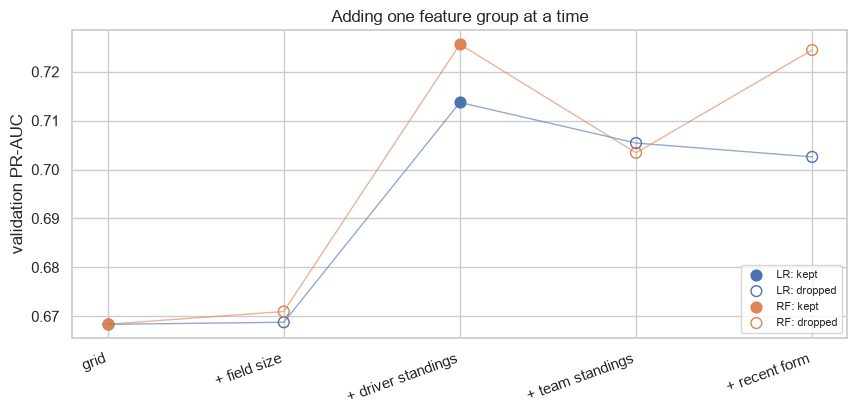

In [37]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(ladder))
for m, colour in [("LR", "C0"), ("RF", "C1")]:
    y = ladder[f"{m} val PR-AUC"]
    ax.plot(x, y, color=colour, lw=1, alpha=0.6)
    ax.scatter(x[ladder["kept"]], y[ladder["kept"]], color=colour, s=60, label=f"{m}: kept")
    ax.scatter(x[~ladder["kept"]], y[~ladder["kept"]], facecolors="none", edgecolors=colour, s=60, label=f"{m}: dropped")
ax.set_xticks(x, ladder["step"], rotation=20, ha="right")
ax.set(ylabel="validation PR-AUC", title="Adding one feature group at a time")
ax.legend(loc="lower right", fontsize=8)
save("fig_14_feature_ladder")
plt.show()

**Reading the table and the plot**
- **Driver standings** are the only group that clears the bar: validation PR-AUC goes from 0.668 to 0.714 (LR) and 0.724 (RF). How the driver is doing *this season* is the strongest addition to the grid.
- **Field size** adds nothing (+0.000 for both models), far below the 0.005 bar. `grid` already says where the driver starts.
- **Team standings** make both models *worse* (−0.008 LR, −0.019 RF), and **recent form** does not help either (−0.011 LR, +0.001 RF). They mostly repeat the driver standings (see the correlation heatmap), and the extra columns add noise.
- **All 11 candidates at once** score lower (LR 0.702, RF 0.719) than the selected set (0.714, 0.724). More features are not better here.

**Chosen features (4):** `grid`, `drv_pos`, `drv_pts_share`, `drv_wins`.

*Limit of this method:* the result can depend on the order in which groups are added, and a dropped group is not tried again. The "all candidates" row and the ablation in 15.1 are checks on that.

### 11.2b Is the choice more than chance?

The 0.005 bar is a rule of thumb. Two statistical checks back it:

1. **Redundancy (VIF).** The variance inflation factor of a column says how well the *other* columns predict it: 1 means not at all, above about 5 means the column is mostly a copy. Columns that are copies add no new information, only noise.
2. **Each step against chance (paired bootstrap).** The validation races are redrawn 2,000 times (whole races, with repeats). Both versions of the model are rescored on the same redrawn rows, so the change in PR-AUC comes with a 95% range and a two-sided p-value. A step is a real improvement when its range stays above 0.

The first table also repeats the Spearman correlation with a p-value. With about 22,000 training rows every p-value is tiny, so the *size* of the correlation is what matters, and the VIF columns show which of the strong candidates are only repeating each other.

In [ ]:
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

def vif(cols):
    """1 / (1 - R^2) of each column when the other columns try to predict it (train rows, medians for gaps)."""
    Z = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(tr[cols].astype(float)), columns=cols)
    r2 = {c: LinearRegression().fit(Z.drop(columns=c), Z[c]).score(Z.drop(columns=c), Z[c]) for c in cols}
    return pd.Series({c: 1 / max(1 - v, 1e-6) for c, v in r2.items()})      # exact copies are capped at 1,000,000

assoc = {c: spearmanr(tr[c], tr["podium"], nan_policy="omit") for c in CANDIDATES}
select_stats = pd.DataFrame({"Spearman rho": {c: r[0] for c, r in assoc.items()},
                             "p-value": {c: r[1] for c, r in assoc.items()},
                             "VIF (all candidates)": vif(CANDIDATES),
                             "VIF (selected only)": vif(SELECTED).reindex(CANDIDATES)})
select_stats["selected"] = select_stats.index.isin(SELECTED)
display(select_stats.sort_values("Spearman rho", key=abs, ascending=False).round(3))

def ladder_preds(cols):
    (Xtr, Xva, _), _ = prepare(cols)
    return {m: make().fit(Xtr, y_train).predict_proba(Xva)[:, 1] for m, make in LADDER_MODELS.items()}

yv = y_val.to_numpy()
by_race = list(va.reset_index(drop=True).groupby("raceId").indices.values())
rng = np.random.default_rng(0)
sel_redraws = [np.concatenate([by_race[i] for i in rng.integers(0, len(by_race), len(by_race))]) for _ in range(2000)]

step_rows, ref, kept_cols = [], None, []
for (group, cols), was_kept in zip(GROUPS.items(), ladder["kept"]):
    cur = ladder_preds(kept_cols + cols)
    if ref is not None:                                   # compare with the last kept version
        for m in cur:
            d = np.array([average_precision_score(yv[r], cur[m][r]) - average_precision_score(yv[r], ref[m][r])
                          for r in sel_redraws])
            step_rows.append({"step": f"+ {group}", "model": m,
                              "PR-AUC change": average_precision_score(yv, cur[m]) - average_precision_score(yv, ref[m]),
                              "95% low": np.percentile(d, 2.5), "95% high": np.percentile(d, 97.5),
                              "p-value": min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean())), "kept": was_kept})
    if was_kept:
        ref, kept_cols = cur, kept_cols + cols
pd.DataFrame(step_rows).round(4)

**Reading the tables**
- **Driver standings are the only step the statistics back.** The change is +0.045 for logistic regression (95% range 0.007 to 0.080, p = 0.014) and +0.056 for the forest (0.017 to 0.093, p = 0.006): both ranges lie above 0, and both changes are far above the 0.005 bar.
- **Every dropped group has a range that includes 0.** Field size: +0.000 and +0.000. Team standings: −0.008 (−0.021 to +0.004) and −0.019 (−0.040 to +0.004). Recent form: −0.011 (−0.034 to +0.014) and +0.001 (−0.016 to +0.019), with p-values from 0.10 to 1.00. None of these changes can be told apart from noise, and the rule and the bootstrap agree for every step.
- **The VIF column explains why.** With all 11 candidates present, `grid` (62.6) and `grid_rel` (59.3) are copies of each other, and the points shares of the driver (7.1) and the team (7.6) are mostly copies of the other standings columns. The selected four have VIFs between 1.6 and 3.5, so each still adds something the others do not.
- **The Spearman p-values are all below 0.001** (printed as 0.0). With 22,000 rows even a correlation of −0.05 (`field_size`) is "significant", so the p-value alone cannot select features; the size of the correlation and the redundancy check do the work.

### 11.3 The chosen features after preprocessing

Effect of imputing and scaling on the chosen features: missing values are filled with train medians, and train ends up with mean 0 and std 1. Validation and test are close but not exact, which shows the scaler was not refit on them. Scaling only shifts and stretches the values, so the shape of each distribution stays the same.

train medians used to fill missing values: {'grid': np.float64(12.0), 'drv_pos': np.float64(12.0), 'drv_pts_share': np.float64(0.077), 'drv_wins': np.float64(0.0)}


raw train                   scaled train      scaled test      
                   mean   std  min    max         mean  std        mean   std
grid              11.98  6.86  1.0   34.0          0.0  1.0       -0.22  0.84
drv_pos           13.19  9.27  1.0  102.0         -0.0  1.0       -0.27  0.67
drv_pts_share      0.21  0.29  0.0    1.0         -0.0  1.0        0.18  1.06
drv_wins           0.36  1.07  0.0   13.0         -0.0  1.0        0.23  1.84

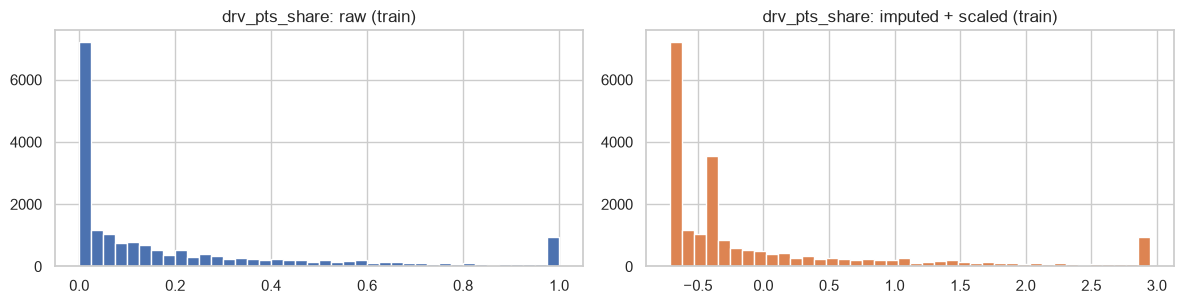

In [38]:
(X_train, X_val, X_test), prep = prepare(SELECTED)
FEATURES = SELECTED
assert not pd.concat([X_train, X_val, X_test]).isna().any().any()

print("train medians used to fill missing values:", dict(zip(FEATURES, prep[0].statistics_.round(3))))
display(pd.concat({"raw train": tr[FEATURES].astype(float).agg(["mean", "std", "min", "max"]).T,
                   "scaled train": X_train.agg(["mean", "std"]).T,
                   "scaled test": X_test.agg(["mean", "std"]).T}, axis=1).round(2))

col = "drv_pts_share" if "drv_pts_share" in FEATURES else FEATURES[-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(tr[col].dropna(), bins=40)
axes[0].set_title(f"{col}: raw (train)")
axes[1].hist(X_train[col], bins=40, color="C1")
axes[1].set_title(f"{col}: imputed + scaled (train)")
plt.tight_layout()
save("fig_15_scaling")
plt.show()

## 12. Baseline, logistic regression, random forest

All models use the same rows and the same inputs.
- **Baseline:** logistic regression on `grid` only, the simplest reasonable model. The other models have to beat it.
- **Logistic regression**: a weighted sum of the inputs passed through a sigmoid. It can only learn straight-line (monotonic) effects.
- **Random forest**: many decision trees on random subsets of rows and features, averaged. It can learn curved effects and interactions, but it is harder to interpret.

**Tuning on validation:** every combination of class weight (none / `balanced`, which gives the rare podium rows more weight) and model settings (`C` for logistic regression; depth and minimum leaf size for the forest). The combination with the best validation PR-AUC is kept.
**Threshold:** the models output a probability. The cut-off for "podium = yes" is the one with the best F1 on validation.

In [39]:
def metrics(y, p, thr):
    """PR-AUC and ROC-AUC use the probabilities; the others need yes/no at threshold thr."""
    yhat = (p >= thr).astype(int)
    return {"PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p), "F1": f1_score(y, yhat),
            "Precision": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat),
            "Accuracy": accuracy_score(y, yhat)}

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    return thr[(2 * prec * rec / (prec + rec + 1e-12))[:-1].argmax()]

MODELS = {
    "LR": (lambda cw, **k: LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED, **k),
           [{"C": c} for c in (0.01, 0.1, 1, 10)]),
    "RF": (lambda cw, **k: RandomForestClassifier(n_estimators=300, class_weight=cw, random_state=SEED, n_jobs=-1, **k),
           [{"max_depth": d, "min_samples_leaf": l} for d in (4, 6, 8) for l in (20, 50)]),
}
rows, fitted = [], []
for name, (make, settings) in MODELS.items():
    for cw in (None, "balanced"):
        for params in settings:
            model = make(cw, **params).fit(X_train, y_train)
            rows.append({"model": name, "class_weight": cw or "none", "settings": str(params),
                         "val PR-AUC": average_precision_score(y_val, model.predict_proba(X_val)[:, 1])})
            fitted.append(model)
tuning = pd.DataFrame(rows)
best = tuning.groupby("model")["val PR-AUC"].idxmax()
lr_best, rf_best = fitted[best["LR"]], fitted[best["RF"]]
rf_best.set_params(n_jobs=1)  # one thread = same summation order, so a score sitting on the threshold never flips
display(tuning.pivot_table(index=["model", "settings"], columns="class_weight", values="val PR-AUC").round(4))
tuning.loc[best]

class_weight                                    balanced    none
model settings                                                  
LR    {'C': 0.01}                                 0.7106  0.7111
      {'C': 0.1}                                  0.7111  0.7137
      {'C': 10}                                   0.7113  0.7138
      {'C': 1}                                    0.7113  0.7137
RF    {'max_depth': 4, 'min_samples_leaf': 20}    0.7166  0.7228
      {'max_depth': 4, 'min_samples_leaf': 50}    0.7166  0.7151
      {'max_depth': 6, 'min_samples_leaf': 20}    0.7232  0.7256
      {'max_depth': 6, 'min_samples_leaf': 50}    0.7232  0.7186
      {'max_depth': 8, 'min_samples_leaf': 20}    0.7182  0.7201
      {'max_depth': 8, 'min_samples_leaf': 50}    0.7223  0.7193

,model,class_weight,settings,val PR-AUC
3,LR,none,{'C': 10},0.713780
10,RF,none,"{'max_depth': 6, 'min_samples_leaf': 20}",0.725603


In [40]:
base_lr = LogisticRegression(max_iter=2000).fit(X_train[["grid"]], y_train)
score = {
    "Baseline (LR on grid)": lambda X: base_lr.predict_proba(X[["grid"]])[:, 1],
    "Logistic regression": lambda X: lr_best.predict_proba(X)[:, 1],
    "Random forest": lambda X: rf_best.predict_proba(X)[:, 1],
}

## 13. Shallow neural network

Built with Keras / TensorFlow on the same inputs:
- 1 or 2 hidden `Dense` layers with ReLU. Sizes (16), (32) and (32 → 16) are tried.
- One sigmoid output neuron = podium probability; binary cross-entropy loss; Adam optimiser.
- **Early stopping:** training stops when the validation loss has not improved for 15 epochs, and the weights roll back to the best epoch. This prevents overfitting.

The size with the best validation PR-AUC is kept.

,hidden layers,epochs run,val PR-AUC
0,"(16,)",200,0.7273
1,"(32,)",200,0.7248
2,"(32, 16)",198,0.7263


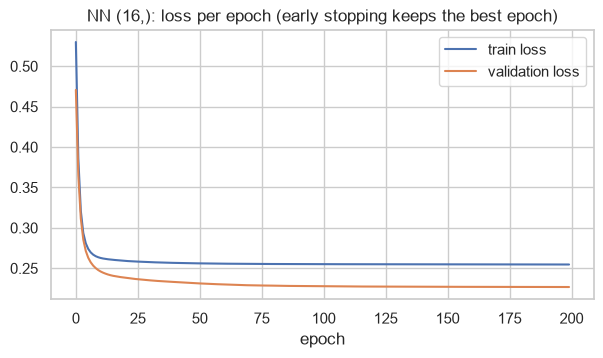

In [41]:
def build_nn(units):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(len(FEATURES),))]
                             + [layers.Dense(u, activation="relu") for u in units]
                             + [layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy")
    return model

nn_rows, nn_models, nn_history = [], {}, {}
for units in [(16,), (32,), (32, 16)]:
    model = build_nn(units)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    h = model.fit(X_train.to_numpy("float32"), y_train.to_numpy(), validation_data=(X_val.to_numpy("float32"), y_val.to_numpy()),
                  epochs=200, batch_size=256, callbacks=[stop], verbose=0)
    p = model.predict(X_val.to_numpy("float32"), verbose=0).ravel()
    nn_rows.append({"hidden layers": str(units), "epochs run": len(h.history["loss"]),
                    "val PR-AUC": average_precision_score(y_val, p)})
    nn_models[str(units)], nn_history[str(units)] = model, h.history
nn_tuning = pd.DataFrame(nn_rows)
nn_units = nn_tuning.loc[nn_tuning["val PR-AUC"].idxmax(), "hidden layers"]
nn_best = nn_models[nn_units]
score["Neural network"] = lambda X: nn_best.predict(X.to_numpy("float32"), verbose=0).ravel()
display(nn_tuning.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(nn_history[nn_units]["loss"], label="train loss")
ax.plot(nn_history[nn_units]["val_loss"], label="validation loss")
ax.set(xlabel="epoch", title=f"NN {nn_units}: loss per epoch (early stopping keeps the best epoch)")
ax.legend()
save("fig_16_nn_loss")
plt.show()

All four models on train and validation, with thresholds chosen on validation. The test set is still unused.

thresholds: {'Baseline (LR on grid)': 0.427, 'Logistic regression': 0.399, 'Random forest': 0.431, 'Neural network': 0.329}


PR-AUC  ROC-AUC     F1  Precision  Recall  \
Baseline (LR on grid) train   0.487    0.881  0.534      0.533   0.535   
                      val     0.668    0.918  0.712      0.712   0.712   
Logistic regression   train   0.545    0.891  0.535      0.565   0.507   
                      val     0.714    0.928  0.709      0.702   0.716   
Random forest         train   0.567    0.900  0.545      0.587   0.508   
                      val     0.726    0.939  0.724      0.715   0.733   
Neural network        train   0.550    0.895  0.563      0.516   0.620   
                      val     0.727    0.936  0.720      0.659   0.794   

                             Accuracy  
Baseline (LR on grid) train     0.876  
                      val       0.914  
Logistic regression   train     0.882  
                      val       0.912  
Random forest         train     0.887  
                      val       0.916  
Neural network        train     0.872  
                      val       0.907

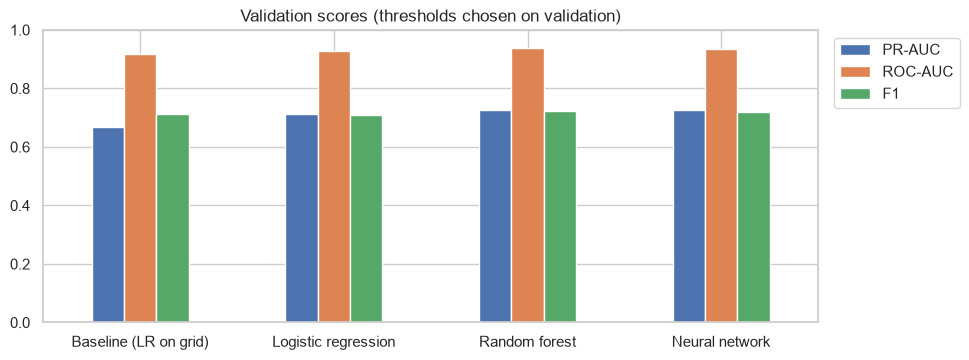

In [42]:
THR = {m: best_f1_threshold(y_val, f(X_val)) for m, f in score.items()}
SETS = {"train": (X_train, y_train), "val": (X_val, y_val)}
results = pd.DataFrame({(m, s): metrics(y, f(X), THR[m]) for m, f in score.items() for s, (X, y) in SETS.items()}).T
print("thresholds:", {m: round(float(t), 3) for m, t in THR.items()})
display(results.round(3))

ax = results.xs("val", level=1)[["PR-AUC", "ROC-AUC", "F1"]].plot.bar(rot=0, figsize=(10, 3.8), ylim=(0, 1))
ax.set_title("Validation scores (thresholds chosen on validation)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save("fig_17_models_val")
plt.show()
for m in ["Logistic regression", "Random forest", "Neural network"]:
    assert results.loc[(m, "val"), "PR-AUC"] > results.loc[("Baseline (LR on grid)", "val"), "PR-AUC"], m

**Reading the comparison**
- All three models beat the grid-only baseline on validation PR-AUC: 0.714 (LR), 0.726 (RF) and 0.727 (NN), against 0.668. The forest and the network are tied; validation has only 243 podiums, so a 0.001 gap is noise.
- Tuning: no class weighting was better for both models. For logistic regression, `C` barely matters (0.711–0.714). The best forest has depth 6 and at least 20 rows per leaf. The three network sizes score within 0.003 of each other, so the smallest one (16 units) is kept: with 4 inputs, a bigger network gains nothing. It trained for the full 200 epochs (the validation loss was still creeping down).
- Train scores are *lower* than validation (PR-AUC 0.55–0.57 against 0.71–0.73). This is not underfitting: the training seasons include the 1950s–80s, with bigger fields and far less predictable races. There is also no sign of overfitting (train is not far above validation).
- **Limitations:** logistic regression can only learn effects that keep going in one direction. The forest learns curves and interactions but is harder to read. The network is a black box and depends on scaling and random initialisation.

## 14. Final scores on the unseen test seasons (2022–2024)

Features, settings and thresholds are now fixed, so the test set is scored **once**.

PR-AUC  ROC-AUC     F1  Precision  Recall  \
Baseline (LR on grid) train   0.487    0.881  0.534      0.533   0.535   
                      val     0.668    0.918  0.712      0.712   0.712   
                      test    0.647    0.914  0.649      0.650   0.647   
Logistic regression   train   0.545    0.891  0.535      0.565   0.507   
                      val     0.714    0.928  0.709      0.702   0.716   
                      test    0.708    0.930  0.678      0.690   0.667   
Random forest         train   0.567    0.900  0.545      0.587   0.508   
                      val     0.726    0.939  0.724      0.715   0.733   
                      test    0.718    0.940  0.667      0.711   0.627   
Neural network        train   0.550    0.895  0.563      0.516   0.620   
                      val     0.727    0.936  0.720      0.659   0.794   
                      test    0.699    0.938  0.683      0.610   0.775   

                             Accuracy  
Baseline (LR on grid) train     0.876  
                      val       0.914  
                      test      0.895  
Logistic regression   train     0.882  
                      val       0.912  
                      test      0.905  
Random forest         train     0.887  
                      val       0.916  
                      test      0.906  
Neural network        train     0.872  
                      val       0.907  
                      test      0.892

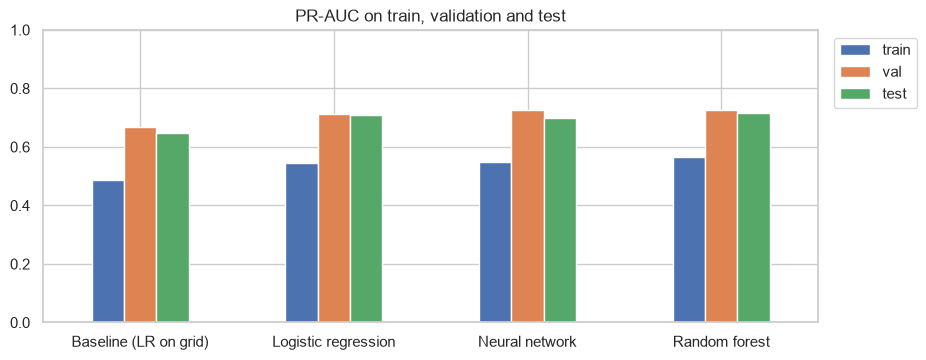

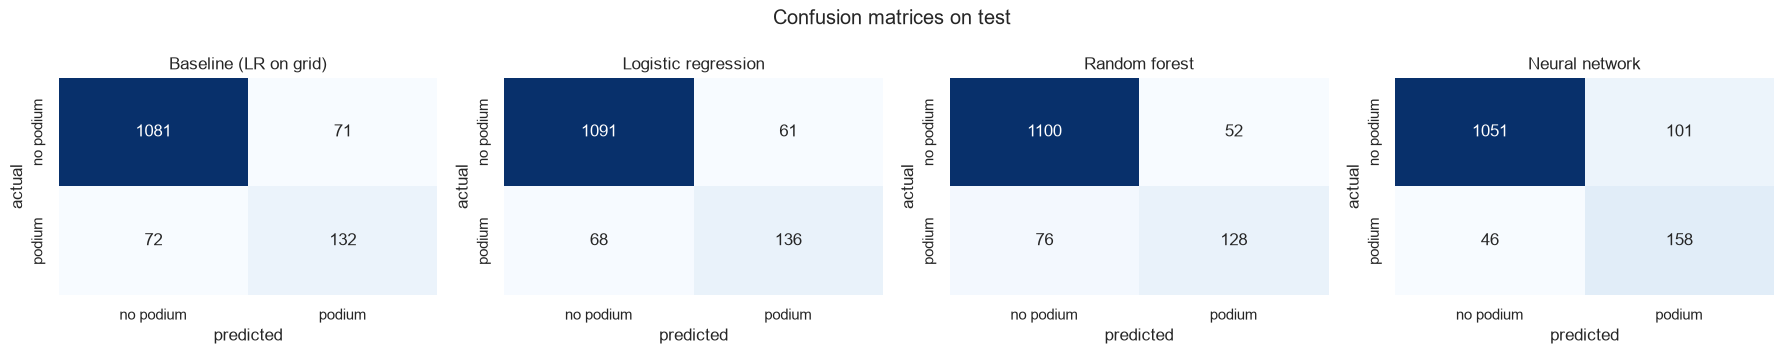

In [43]:
SETS["test"] = (X_test, y_test)
final = pd.DataFrame({(m, s): metrics(y, f(X), THR[m]) for m, f in score.items() for s, (X, y) in SETS.items()}).T
display(final.round(3))

ax = final["PR-AUC"].unstack()[["train", "val", "test"]].plot.bar(rot=0, figsize=(10, 3.8), ylim=(0, 1))
ax.set_title("PR-AUC on train, validation and test")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
save("fig_18_pr_auc_splits")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, (m, f) in zip(axes, score.items()):
    cm = confusion_matrix(y_test, f(X_test) >= THR[m])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no podium", "podium"], yticklabels=["no podium", "podium"])
    ax.set(title=m, xlabel="predicted", ylabel="actual")
plt.suptitle("Confusion matrices on test")
plt.tight_layout()
save("fig_19_confusion_test")
plt.show()

**Reading the test results**
- Every model beats the baseline on test: random forest 0.718, logistic regression 0.708, neural network 0.699, baseline 0.647.
- Test scores are close to validation (within 0.03). Settings and thresholds were chosen on validation, and 2022–2024 is a new rules era, so a small drop is expected.
- F1 on test is 0.67–0.68 for the three models.
- **Final model: the neural network**, because it has the best *validation* PR-AUC (the primary metric). On test the forest scores higher, but the choice must not be made on test. The three models are within about 0.02 of each other on both sets, so the honest summary is that they perform about the same.

## 15. Experiments

### 15.1 Feature-group ablation

Remove one kept group at a time, retrain logistic regression and the random forest with their chosen settings, and measure how much PR-AUC drops. Section 11 justified each group *before* training; this measures what each one contributes *after* training.

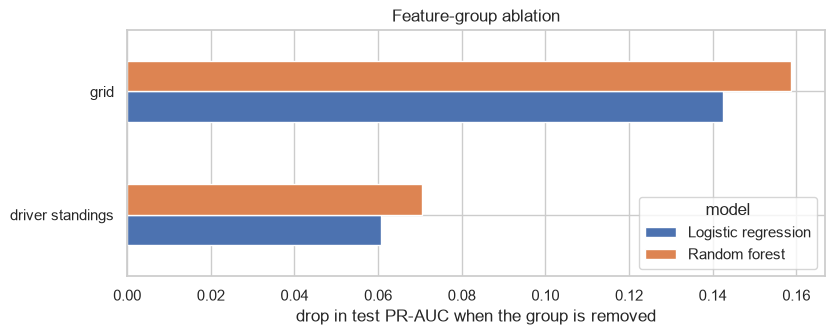

,without,model,val drop,test drop
0,grid,Logistic regression,0.078,0.143
1,grid,Random forest,0.095,0.159
2,driver standings,Logistic regression,0.045,0.061
3,driver standings,Random forest,0.057,0.070


In [44]:
ABLATE = {g: cols for g, cols in GROUPS.items() if set(cols) <= set(SELECTED)}
full = {m: (final.loc[(m, "val"), "PR-AUC"], final.loc[(m, "test"), "PR-AUC"])
        for m in ["Logistic regression", "Random forest"]}
rows = []
for group, cols in ABLATE.items():
    (Xtr, Xva, Xte), _ = prepare([c for c in SELECTED if c not in cols])
    for m, model in [("Logistic regression", lr_best), ("Random forest", rf_best)]:
        fit = clone(model).fit(Xtr, y_train)
        rows.append({"without": group, "model": m,
                     "val drop": full[m][0] - average_precision_score(y_val, fit.predict_proba(Xva)[:, 1]),
                     "test drop": full[m][1] - average_precision_score(y_test, fit.predict_proba(Xte)[:, 1])})
ablation = pd.DataFrame(rows)

ax = ablation.pivot(index="without", columns="model", values="test drop").plot.barh(figsize=(9, 3.2))
ax.set(xlabel="drop in test PR-AUC when the group is removed", ylabel="", title="Feature-group ablation")
save("fig_20_ablation")
plt.show()
ablation.round(3)

**Reading the ablation**
- **`grid` matters most:** removing it costs 0.14 (LR) and 0.16 (RF) of test PR-AUC, and 0.08–0.10 on validation.
- **Driver standings** matter too: removing them costs 0.06–0.07 on test and 0.05–0.06 on validation.
- Both kept groups help on validation *and* on test, so the selection from section 11 holds up after training.

### 15.2 Preprocessing-order experiments

Logistic regression and the random forest are retrained with everything else unchanged; only the preprocessing differs. Each is scored on validation.

**Experiment 1: fit the imputer and scaler before or after splitting?** The leaky version learns the medians, means and standard deviations from all seasons, including validation and test.

In [45]:
def val_scores(pipe=None, fit_on=None):
    (Xtr, Xva, _), _ = prepare(SELECTED, pipe, fit_on)
    return {m: average_precision_score(y_val, clone(model).fit(Xtr, y_train).predict_proba(Xva)[:, 1])
            for m, model in [("Logistic regression", lr_best), ("Random forest", rf_best)]}

exp1 = pd.DataFrame({"fit on train only (used)": val_scores(),
                     "fit on all seasons (leaky)": val_scores(fit_on=mt)})
exp1["difference"] = exp1.iloc[:, 1] - exp1.iloc[:, 0]
exp1.round(4)

,fit on train only (used),fit on all seasons (leaky),difference
Logistic regression,0.7138,0.7137,-0.0001
Random forest,0.7256,0.7252,-0.0004


**Experiment 2: impute then scale, or scale then impute?** When scaling comes first, the scaler's mean and standard deviation are computed on the real values only, before the medians are filled in.

In [46]:
exp2 = pd.DataFrame({"impute -> scale (used)": val_scores(),
                     "scale -> impute": val_scores(make_pipeline(StandardScaler(), SimpleImputer(strategy="median")))})
exp2["difference"] = exp2.iloc[:, 1] - exp2.iloc[:, 0]
exp2.round(4)

,impute -> scale (used),scale -> impute,difference
Logistic regression,0.7138,0.7138,0.0
Random forest,0.7256,0.7256,0.0


**Are these differences more than chance?** A paired bootstrap: redraw the validation races 2,000 times (whole races, with repeats), and on each redraw rescore *both* versions on the same rows. The p-value is how often the difference lands on the other side of zero (two-sided); the 95% range is the middle 95% of the 2,000 differences.

In [47]:
def val_preds(pipe=None, fit_on=None):
    (Xtr, Xva, _), _ = prepare(SELECTED, pipe, fit_on)
    return {m: clone(model).fit(Xtr, y_train).predict_proba(Xva)[:, 1]
            for m, model in [("Logistic regression", lr_best), ("Random forest", rf_best)]}

used = val_preds()
variants = {"1: fit on all seasons": val_preds(fit_on=mt),
            "2: scale -> impute": val_preds(make_pipeline(StandardScaler(), SimpleImputer(strategy="median")))}
yv = y_val.to_numpy()
races = list(va.reset_index(drop=True).groupby("raceId").indices.values())
rng = np.random.default_rng(0)
redraws = [np.concatenate([races[i] for i in rng.integers(0, len(races), len(races))]) for _ in range(2000)]

rows = []
for exp, alt in variants.items():
    for m in used:
        d = np.array([average_precision_score(yv[r], alt[m][r]) - average_precision_score(yv[r], used[m][r]) for r in redraws])
        rows.append({"experiment": exp, "model": m,
                     "difference": average_precision_score(yv, alt[m]) - average_precision_score(yv, used[m]),
                     "95% low": np.percentile(d, 2.5), "95% high": np.percentile(d, 97.5),
                     "p-value": min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))})
pd.DataFrame(rows).round(4)

,experiment,model,difference,95% low,95% high,p-value
0,1: fit on all seasons,Logistic regression,-0.0001,-0.0003,0.0002,0.694
1,1: fit on all seasons,Random forest,-0.0004,-0.0012,0.0003,0.293
2,2: scale -> impute,Logistic regression,0.0000,-0.0001,0.0002,0.986
3,2: scale -> impute,Random forest,0.0000,0.0000,0.0000,1.000


**Reading the experiments**
- **Neither difference is significant:** every bootstrap 95% range includes 0, and the p-values are far above 0.05 (experiment 1: 0.69 for LR and 0.29 for RF; experiment 2: 0.99 and 1.00).
- **Experiment 1:** the leaky version changes validation PR-AUC by at most 0.0004. Little leaks here because 88% of all rows are training rows, so the medians, means and standard deviations hardly move, and shifting or stretching a column barely changes logistic regression or a forest. Fitting on train only is still the correct order: it is the only one that is possible when predicting a real future race.
- **Experiment 2:** the order makes no visible difference (0.0000). The filled value is the same point either way; only the scaler's mean and standard deviation differ slightly. Imputing first is kept, so the scaler sees exactly the complete data the model gets.

## 16. Explainability (XAI)

| Question | Tool | Models |
|---|---|---|
| Which inputs does the model's ranking quality depend on? (global) | permutation importance | all four |
| Which inputs push the probability up or down? (global) | SHAP beeswarm and bar plots | logistic regression, random forest, neural network |
| Why this probability for this driver? (local) | SHAP and LIME side by side | the same three models, the same two rows |

- The baseline has a single input (`grid`), so SHAP and LIME have nothing to split; it appears in the permutation plot only.
- **SHAP is in probability units for all three models**, so the models can be compared. The forest uses `TreeExplainer`. Logistic regression and the network use SHAP's model-agnostic *exact* explainer with 100 training rows as the background: with only four inputs it can try every combination of inputs, so the values are exact, not sampled.
- **LIME** is the same for all three: it only needs the model's probabilities.
- Rows: **validation** (2018–2021). Inputs are shown in their **original units** (scaling undone for display only), so `grid = 1` reads as pole position.

> **Explanations are not causes.** An important feature is one the *model relies on* to make predictions. That does not mean it *causes* podiums. For example, a good grid slot is mostly a sign of a fast car, and the fast car is what produces podiums. Features that overlap (the three standings columns) share the credit, and how they share it depends on the method.

In [ ]:
XAI_MODELS = ["Logistic regression", "Random forest", "Neural network"]
SHORT = {"Logistic regression": "lr", "Random forest": "rf", "Neural network": "nn"}

def to_raw(X):
    return pd.DataFrame(prep[-1].inverse_transform(X), columns=FEATURES, index=X.index)

def to_scaled(X_raw):
    return pd.DataFrame(prep.transform(X_raw), columns=FEATURES, index=X_raw.index)

X_val_raw = to_raw(X_val)
names = clean["drivers"].set_index("driverId")
row_label = (names.loc[va["driverId"], "forename"].to_numpy() + " " + names.loc[va["driverId"], "surname"].to_numpy()
             + ", " + va["year"].astype(str).to_numpy() + " " + va["name"].to_numpy())

### 16.1 Permutation importance

Shuffle one column of the validation rows, which breaks its link to the target, and measure how much validation PR-AUC drops. This is repeated 10 times. A bigger drop means the model relies on that input more. It is written as a small loop because sklearn's `permutation_importance` needs a sklearn model, and the Keras network is not one.

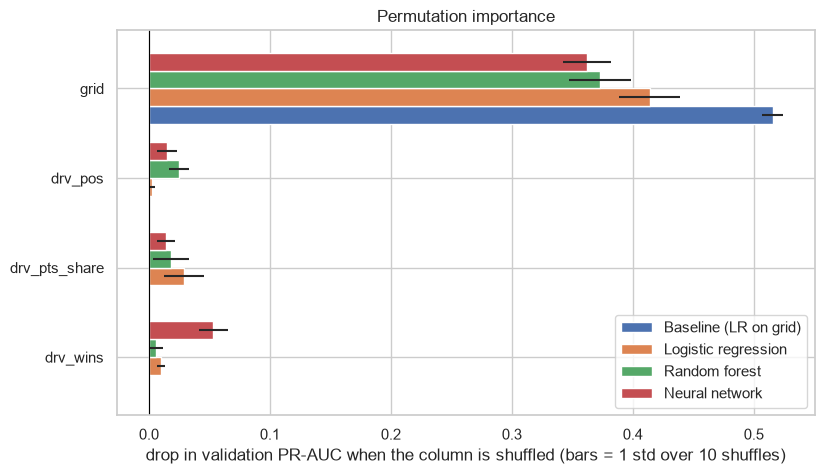

,Baseline (LR on grid),Logistic regression,Random forest,Neural network
grid,0.5155,0.4141,0.3729,0.3623
drv_pos,0.0000,0.0027,0.0251,0.0148
drv_pts_share,0.0000,0.0291,0.0182,0.0142
drv_wins,0.0000,0.0098,0.0057,0.0532


In [49]:
def permutation_drop(f, X, y, repeats=10):
    rng = np.random.default_rng(SEED)
    base = average_precision_score(y, f(X))
    drops = {c: [] for c in X.columns}
    for c in X.columns:
        for _ in range(repeats):
            Xs = X.copy()
            Xs[c] = rng.permutation(Xs[c].to_numpy())
            drops[c].append(base - average_precision_score(y, f(Xs)))
    return pd.DataFrame(drops).agg(["mean", "std"]).T

perm = {m: permutation_drop(f, X_val, y_val) for m, f in score.items()}
perm_mean = pd.DataFrame({m: d["mean"] for m, d in perm.items()})
perm_std = pd.DataFrame({m: d["std"] for m, d in perm.items()})
order = perm_mean["Random forest"].sort_values().index

ax = perm_mean.loc[order].plot.barh(xerr=perm_std.loc[order], width=0.8, figsize=(9, 5))
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="drop in validation PR-AUC when the column is shuffled (bars = 1 std over 10 shuffles)",
       title="Permutation importance")
save("fig_21_permutation_importance")
plt.show()
perm_mean.loc[order[::-1]].round(4)

**Reading the permutation importance**
- **`grid` dominates for every model.** Shuffling it drops validation PR-AUC by 0.37 (RF), 0.41 (LR) and 0.36 (NN). For the baseline the drop is 0.52, which is all of its signal.
- **The standings columns are small, and each model uses a different one.** The forest leans on `drv_pos` (0.025), logistic regression on `drv_pts_share` (0.029), and the network on `drv_wins` (0.053).
- **Why they differ:** the three standings columns all describe how the driver is doing this season, so a model can get that information from any one of them.
- **Caveat:** an input that shares information with another looks less important, because the model can lean on the copy. "Small" means "adds little beyond the other inputs", not "carries no information".

### 16.2 SHAP (global)

For each prediction, SHAP splits *prediction − average prediction* into one contribution per input. The contributions add up exactly to the model's output. The same is done for logistic regression, the forest and the network, so the three can be put side by side.

In [ ]:
background = X_train.sample(100, random_state=SEED)      # training rows used to "switch an input off"

def explain_shap(m):
    """SHAP values of the validation rows, in probability units, for one model."""
    if m == "Random forest":
        out = shap.TreeExplainer(rf_best)(X_val)
        return out[..., 1] if out.values.ndim == 3 else out      # keep the "podium" class
    f = lambda A: score[m](pd.DataFrame(A, columns=FEATURES))
    return shap.Explainer(f, background, algorithm="exact")(X_val)

sv = {m: explain_shap(m) for m in XAI_MODELS}
p_val = {m: score[m](X_val) for m in XAI_MODELS}
for m in XAI_MODELS:
    assert np.allclose(sv[m].base_values + sv[m].values.sum(axis=1), p_val[m], atol=1e-3), m
    print(f"{m}: base value (average predicted probability) = {float(np.mean(sv[m].base_values)):.3f}")

for m in XAI_MODELS:
    plt.close("all")
    shap.summary_plot(sv[m].values, X_val_raw, show=False)
    plt.title(f"SHAP, {m}: one dot per driver-race (right = raises the podium probability)")
    save(f"fig_22_shap_beeswarm_{SHORT[m]}")
    plt.show()

shap_mean = pd.DataFrame({m: pd.Series(np.abs(sv[m].values).mean(axis=0), index=FEATURES) for m in XAI_MODELS})
order = shap_mean["Random forest"].sort_values().index
ax = shap_mean.loc[order].plot.barh(width=0.8, figsize=(9, 4.5))
ax.set(xlabel="mean |SHAP| on validation rows (probability units)", title="SHAP: average size of each input's contribution")
save("fig_23_shap_bar")
plt.show()

plt.close("all")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, shap_mean["Random forest"].sort_values(ascending=False).index[:3]):
    shap.dependence_plot(col, sv["Random forest"].values, X_val_raw, interaction_index=None, ax=ax, show=False)
    ax.axhline(0, color="black", lw=0.6)
plt.suptitle("SHAP dependence, random forest")
plt.tight_layout()
save("fig_24_shap_dependence")
plt.show()

pd.concat({"mean |SHAP|": shap_mean,
           "SHAP rank": shap_mean.rank(ascending=False).astype(int),
           "permutation rank": perm_mean[XAI_MODELS].rank(ascending=False).astype(int)}, axis=1).loc[order[::-1]].round(4)

**Reading the SHAP plots (random forest)**
- **Base value 0.133:** the forest's average podium probability. Each prediction is this value plus the inputs' contributions.
- **`grid` is first by far:** mean |SHAP| 0.104, about 2.5 times the next input. In the beeswarm, low grid numbers (blue) push the probability *up* by up to about +0.35, and high grid numbers (red) push it down. The dependence plot shows the shape: a steep fall over the first few slots, then flat further back. From the second half of the grid, the exact slot barely changes the answer.
- After `grid`: `drv_pos` 0.041, `drv_pts_share` 0.027, `drv_wins` 0.007. A better championship position and more points raise the probability.
- **SHAP and permutation importance give the same order** for the forest (`grid`, `drv_pos`, `drv_pts_share`, `drv_wins`), although they measure different things: permutation measures lost *ranking quality*, SHAP how far an input *moves the probability*.

**Comparing the three models**
- All three models use the same four inputs and SHAP values are in the same units, so the bars in the bar chart are directly comparable.
- Logistic regression's contribution for an input is a straight line in that input (its coefficient times how far the value is from the average), so it cannot bend. The forest and the network can: the dependence plot above shows the forest's steep fall over the first few grid slots, which a straight line can only approximate.
- The three standings inputs overlap, so where the credit goes between them can differ from model to model even when the predictions are similar. The rank table shows this next to the permutation ranks.

### 16.3 Local explanations: SHAP and LIME

Two validation rows are picked by a rule rather than by hand, using the random forest's probabilities, and the **same two rows are explained for all three models**:
- **hit**: the true podium finisher the forest was *most* sure about;
- **miss**: the true podium finisher the forest was *least* sure about (the biggest surprise).

For each model and row, one figure shows the SHAP contributions (left) and the LIME weights (right); red raises the podium probability, blue lowers it. LIME perturbs the row many times, asks the model about each copy, and fits a small linear model around the row. It works on the original units. The figure title gives how well that small model fits (R²).

In [ ]:
ROWS = {"hit": int(np.where(y_val == 1, p_val["Random forest"], -1).argmax()),
        "miss": int(np.where(y_val == 1, p_val["Random forest"], 2).argmin())}

lime_explainer = LimeTabularExplainer(to_raw(X_train).to_numpy(), feature_names=FEATURES,
                                      class_names=["no podium", "podium"], discretize_continuous=True, random_state=SEED)

def lime_weights(m, i):
    """LIME explanation of validation row i for model m: the explanation and one weight per input."""
    def predict_raw(A):
        p = score[m](to_scaled(pd.DataFrame(A, columns=FEATURES)))
        return np.column_stack([1 - p, p])
    exp = lime_explainer.explain_instance(X_val_raw.iloc[i].to_numpy(), predict_raw, num_features=len(FEATURES), num_samples=5000)
    return exp, pd.Series({FEATURES[j]: w for j, w in exp.as_map()[1]})

for tag, i in ROWS.items():
    print(f"{tag.upper()}: {row_label[i]} | grid {X_val_raw['grid'].iloc[i]:.0f} | podium: yes | P(podium): "
          + ", ".join(f"{m} {p_val[m][i]:.2f}" for m in XAI_MODELS))

In [ ]:
local = {}
for m in XAI_MODELS:
    for tag, i in ROWS.items():
        exp, lime_w = lime_weights(m, i)
        t = pd.DataFrame({"value": X_val_raw.iloc[i], "SHAP": pd.Series(sv[m].values[i], index=FEATURES), "LIME": lime_w})
        t["same direction"] = np.sign(t["SHAP"]) == np.sign(t["LIME"])
        local[m, tag] = t

        order = t["SHAP"].abs().sort_values().index
        labels = [f"{f} = {t.loc[f, 'value']:.3g}" for f in order]
        fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
        for ax, col in zip(axes, ["SHAP", "LIME"]):
            vals = t.loc[order, col]
            ax.barh(labels, vals, color=np.where(vals >= 0, "C3", "C0"))
            ax.axvline(0, color="black", lw=0.8)
            ax.set_title(col)
        fig.suptitle(f"{m}: {row_label[i]}  (P(podium) = {p_val[m][i]:.2f}, LIME local fit R² = {exp.score:.2f})", y=1.05)
        save(f"fig_25_local_{tag}_{SHORT[m]}")
        plt.show()

agree = pd.concat(local, names=["model", "row", "input"])
display(agree.round(3))
agree.groupby(level=["model", "row"])["same direction"].mean().unstack().round(2)

**Reading the local explanations**

*Hit: Lewis Hamilton, 2018 United States Grand Prix* (pole position). For the forest P(podium) = 0.84. Starting from the average 0.133, `grid = 1` adds the most (+0.35), then `drv_pos = 1` (+0.15), `drv_pts_share = 1.0` (+0.12) and `drv_wins = 9` (+0.10). That is the championship leader starting on pole. LIME agrees on every direction and puts `grid` first as well. Its local model fits well (R² 0.82).

*Miss: Daniil Kvyat, 2019 German Grand Prix* (started 14th, finished 3rd). For the forest P(podium) = 0.02. Every input pushes *down*: `grid = 14` (−0.07), `drv_pos = 14` (−0.03), few points (−0.02) and no wins. Given what is known before the start, the forest's answer is reasonable. That race was wet and chaotic (outside knowledge, not in the data), which pre-race information cannot contain. LIME again agrees on every direction, but its local model fits poorly here (R² 0.15), so for this row SHAP's numbers are more trustworthy.

**Across the three models:** the table gives, for each model and row, the SHAP weight, the LIME weight and whether they point the same way; the last table is the share of inputs where they agree. The same two rows are explained for every model, so the figures differ only because the models differ. Where the printed probabilities differ a lot between models, the bars show which input each model reads differently.

**SHAP vs LIME:** SHAP splits the difference from the average prediction exactly among the inputs (the values add up). LIME fits a small linear model on random perturbations, and its weights do not need to add up to anything. Both explain *these* models on 2018–2021 rows, not Formula 1 itself.

## 17. Inference functions

`PREDICT[model]` is one inference function **per model**. Each takes one driver-race as a dictionary of pre-race features in their normal units and returns that model's probability and its yes/no at the model's validation threshold. Missing or unknown values are allowed: they are filled with the train medians, exactly as in training, and no row is dropped. `predict_podium` is the function of the model with the best validation PR-AUC.

In [ ]:
FINAL_MODEL = final.xs("val", level=1)["PR-AUC"].drop("Baseline (LR on grid)").idxmax()

def make_predictor(name):
    def predict(record):
        """record: dict of pre-race features (missing keys allowed). Returns this model's probability and yes/no."""
        X = pd.DataFrame([record], columns=FEATURES).astype(float)      # missing features become NaN
        p = float(score[name](to_scaled(X))[0])
        return {"model": name, "P(podium)": round(p, 3), "podium": bool(p >= THR[name])}
    return predict

PREDICT = {m: make_predictor(m) for m in score}      # one inference function per model
predict_podium = PREDICT[FINAL_MODEL]
print("final model:", FINAL_MODEL)

def all_models(record):
    return pd.DataFrame([f(record) for f in PREDICT.values()]).set_index("model")

# 1) A complete record: the first 2024 pole sitter with every feature known (a test row)
row = te[(te["year"] == 2024) & (te["grid"] == 1)].dropna(subset=FEATURES).sort_values("race_idx").iloc[0]
complete = row[FEATURES].astype(float).to_dict()
print(f"complete record ({names.loc[row['driverId'], 'surname']}, {row['name']} {row['year']}):",
      {k: round(v, 3) for k, v in complete.items()}, "| actual podium:", bool(row["podium"]))
display(all_models(complete))

# 2) A partially-missing record: a rookie in round 1 (no standings, no history), starting 4th
partial = {"grid": 4}
print("partial record:", partial)
display(all_models(partial))

# 3) A real test row with missing values: missing features are filled, the row is not dropped
has_gap = te[FEATURES].isna().any(axis=1)
print(f"test rows with at least one missing feature: {has_gap.sum()} of {len(te)} ({has_gap.mean():.1%}); all are scored")
gap = te[has_gap].iloc[0]
record = gap[FEATURES].astype(float).to_dict()
print(f"first one: {names.loc[gap['driverId'], 'surname']}, {gap['name']} {gap['year']}, "
      f"missing: {[k for k, v in record.items() if np.isnan(v)]} | actual podium: {bool(gap['podium'])}")
display(all_models(record))

## 18. Limitations

- **Qualifying coverage drift:** qualifying times exist only from 1994 (Q2/Q3 from 2003 on, and only for the faster drivers). The model therefore uses `grid` (the qualifying result after penalties) and no qualifying times.
- **Era sensitivity:** field sizes, points systems and reliability changed a lot over 75 years. Points are used as a share of the leader's points, and the split is by season, but the 1950s training rows are still very different from the test seasons.
- **Validation and test are dominated by a few teams** (Mercedes 2018–21, Red Bull 2022–24), so the scores and explanations describe those eras.
- **Race-day events are invisible:** rain, crashes, safety cars and failures are not known before the start. The "miss" row in section 16 is an example.
- **Explanations are not causal:** XAI describes what the model relies on, not what makes a driver finish on the podium.